# Baseline models under immutable nested specimen-group CV


**Scientific goal.** Establish the minimum, design-aware statistical, and strong classical performance references. **Input from Notebook 02.** The immutable modeling table, seven permitted predictors, hierarchy, and nine outer folds. **Allowed data.** Outer-training partitions for fitting and inner group folds for tuning; the current outer fold only for OOF prediction. **Methods.** Dummy, a factorial mixed-effects response surface with a specimen random intercept, linear/regularized, polynomial, kernel, and tree baselines. **Output to Notebook 04.** Saved fold models, target-wise OOF predictions, fold uncertainty, residual diagnostics, and timing evidence.


## 1. Environment and immutable modeling inputs

In [1]:
from pathlib import Path
import hashlib
import os
import platform
import sys
import time
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
SEED = 20260820
REQUIRED_FONT = "Times New Roman"
FONT_SIZE_MIN = 16
FONT_SIZE_MAX = 18
FIGURE_DPI = 350
RUN_ID = "FA_ATF_DaKS69_Exploratory_20260820"

ROOT = Path.cwd().resolve()
if not (ROOT / "dataset").exists() and (ROOT.parent / "dataset").exists():
    ROOT = ROOT.parent

RAW_DIR = ROOT / "dataset" / "raw"
UNIFIED_DIR = ROOT / "dataset" / "unified"
RUN_ROOT = ROOT / "artifacts" / RUN_ID
TABLE_ROOT = RUN_ROOT / "Tables"
FIGURE_PNG_DIR = RUN_ROOT / "Figures" / "PNG"
FIGURE_PDF_DIR = RUN_ROOT / "Figures" / "PDF"
FIGURE_SOURCE_DIR = RUN_ROOT / "Tables" / "Figure_Source_Data"
REPORT_DIR = RUN_ROOT / "Reports"
MANIFEST_DIR = RUN_ROOT / "Manifests"
MODEL_DIR = RUN_ROOT / "Models"
PREDICTION_DIR = RUN_ROOT / "Tables" / "Predictions"
METRIC_DIR = RUN_ROOT / "Tables" / "Metrics"
STATISTICS_DIR = RUN_ROOT / "Tables" / "Statistics"
AUDIT_DIR = RUN_ROOT / "Tables" / "Audit"

for directory in (
    RAW_DIR, UNIFIED_DIR, RUN_ROOT, TABLE_ROOT, FIGURE_PNG_DIR, FIGURE_PDF_DIR,
    FIGURE_SOURCE_DIR, REPORT_DIR, MANIFEST_DIR, MODEL_DIR, PREDICTION_DIR,
    METRIC_DIR, STATISTICS_DIR, AUDIT_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)


In [2]:
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
if REQUIRED_FONT not in available_fonts:
    raise RuntimeError("Times New Roman is unavailable; publication figures cannot be generated.")

mpl.rcParams.update({
    "font.family": REQUIRED_FONT,
    "font.serif": [REQUIRED_FONT],
    "mathtext.fontset": "custom",
    "mathtext.rm": REQUIRED_FONT,
    "mathtext.it": REQUIRED_FONT + ":italic",
    "mathtext.bf": REQUIRED_FONT + ":bold",
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 17,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
    "figure.titlesize": 18,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "lines.linewidth": 2.0,
    "figure.dpi": FIGURE_DPI,
    "savefig.dpi": FIGURE_DPI,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.color": "#E7EAED",
    "grid.alpha": 0.80,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

PALETTE = {
    "blue": "#2F6B8F", "orange": "#C77C2B", "green": "#4F7F3A",
    "purple": "#6D5A8D", "red": "#B45A55", "gray": "#6E7378",
    "light_gray": "#E7EAED", "teal": "#4A8C8A", "gold": "#C9A227",
    "black": "#222222", "white": "#FFFFFF",
}

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def validate_figure_typography(fig):
    fig.canvas.draw()
    violations = []
    for text_object in fig.findobj(match=mpl.text.Text):
        if not text_object.get_text().strip():
            continue
        size = float(text_object.get_fontsize())
        resolved_name = text_object.get_fontproperties().get_name()
        if resolved_name != REQUIRED_FONT:
            violations.append(f"font={resolved_name!r}: {text_object.get_text()!r}")
        if not (FONT_SIZE_MIN <= size <= FONT_SIZE_MAX):
            violations.append(f"fontsize={size}: {text_object.get_text()!r}")
    if violations:
        raise AssertionError("Typography QA failed:\n" + "\n".join(violations))

def save_scientific_figure(fig, stem, source_frame):
    source_path = FIGURE_SOURCE_DIR / f"{stem}.csv"
    png_path = FIGURE_PNG_DIR / f"{stem}.png"
    source_frame.to_csv(source_path, index=False)
    validate_figure_typography(fig)
    fig.savefig(png_path, dpi=FIGURE_DPI, bbox_inches="tight", pad_inches=0.08, facecolor="white")
    return png_path, None, source_path

import pickle
import joblib
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from statsmodels.regression.mixed_linear_model import MixedLM

DATA_PATH = UNIFIED_DIR / "modeling_dataset.csv"
data = pd.read_csv(DATA_PATH)
FEATURES = [
    "HV_init_HV30", "feed_mm_rev", "cutting_speed_m_min", "depth_of_cut_mm",
    "uncut_chip_section_mm2", "material_removal_proxy_mm3_min", "theoretical_roughness_Ra_um",
]
HIERARCHICAL_FEATURES = [
    "specimen_id", "HV_init_HV30", "feed_mm_rev",
    "cutting_speed_m_min", "depth_of_cut_mm",
]


TARGETS = ["surface_roughness_Ra_um", "post_process_hardness_HV30"]
if data.groupby("specimen_id").outer_fold.nunique().max() != 1:
    raise RuntimeError("The immutable specimen-group fold contract is invalid.")

FACTOR_LEVELS = {
    factor: np.sort(data[factor].unique()).astype(float)
    for factor in HIERARCHICAL_FEATURES[1:]
}
if any(len(levels) != 3 for levels in FACTOR_LEVELS.values()):
    raise RuntimeError("The hierarchical factorial comparator requires three observed levels per factor.")



## 2. Define balanced inner folds and target-wise metrics

In [3]:
def balanced_inner_splits(frame, n_splits, seed):
    group_info = frame[["specimen_id", "HV_init_HV30"]].drop_duplicates()
    rng = np.random.default_rng(seed)
    fold_by_group = {}
    for hardness in sorted(group_info.HV_init_HV30.unique()):
        groups = group_info.loc[group_info.HV_init_HV30.eq(hardness), "specimen_id"].to_numpy()
        for position, group in enumerate(rng.permutation(groups)):
            fold_by_group[group] = position % n_splits
    assigned = frame.specimen_id.map(fold_by_group).to_numpy()
    splits = []
    for fold in range(n_splits):
        validation = np.flatnonzero(assigned == fold)
        training = np.flatnonzero(assigned != fold)
        if set(frame.iloc[training].specimen_id) & set(frame.iloc[validation].specimen_id):
            raise RuntimeError("Inner-fold specimen leakage detected.")
        splits.append((training, validation))
    return splits

def target_metrics(predictions):
    rows = []
    for (model_name, target), part in predictions.groupby(["model", "target"]):
        y_true, y_pred = part.y_true.to_numpy(), part.y_pred.to_numpy()
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        rows.append({
            "model": model_name, "target": target,
            "MAE": mean_absolute_error(y_true, y_pred), "RMSE": rmse,
            "R2": r2_score(y_true, y_pred), "NRMSE": rmse / np.std(y_true, ddof=1),
        })
    return pd.DataFrame(rows)

## 3. Predeclare compact baseline candidate grids

In [4]:
# Publication-table presentation helper. It changes display only; values are untouched.
def display_grouped_table(
    frame,
    title=None,
    identifier_columns=None,
    column_groups=None,
    row_group_columns=None,
    max_rows_per_block=12,
):
    table = frame.copy()

    def _identifier_columns(columns):
        priorities = [
            "model", "model_family", "rank", "target", "Target", "variant", "Variant",
            "ablation", "comparison", "Comparison", "comparator", "Comparator",
            "class", "Class", "factor", "factor_label", "level", "condition",
            "distance_band", "metric", "Metric", "component",
            "candidate", "expert", "outer_fold", "inner_fold", "fold",
            "Feature", "feature", "Predictor", "predictor", "Variable",
            "variable", "Field", "Decision", "Analysis item", "Scientific conclusion",
            "Scientific property", "Quantity", "Scaler", "Contract item", "criterion",
            "Column", "item", "sample_id", "specimen_id", "section_id",
        ]
        selected = [column for column in priorities if column in columns]
        return selected[:4]

    def _column_groups(columns, identifiers):
        remaining = [column for column in columns if column not in identifiers]
        if len(columns) <= 7:
            return [("Complete table", remaining)]
        rules = [
            ("Predictors and design variables", (
                "hv_init", "feed", "cutting_speed", "depth_of_cut", "uncut_chip",
                "material_removal", "theoretical_roughness", "predictor", "factor",
                "formula", "unit", "level", "role", "definition", "available",
            )),
            ("Measured responses", (
                "surface_roughness", "post_process_hardness", "y_true", "y_pred",
                "lower_90", "upper_90",
            )),
            ("Predictive performance", (
                "mae", "rmse", "nrmse", "r2", "macro", "bias", "error",
                "rank", "score",
            )),
            ("Uncertainty and statistical evidence", (
                "ci_", "_ci", "confidence", "bootstrap", "coverage", "interval",
                "wilcoxon", "holm", "p_value", "_p", "probability", "effect",
                "delta", "median_fold", "sign_flip", "quantile",
            )),
            ("Computational efficiency", (
                "time", "latency", "parameter", "memory", "byte", "epoch",
                "inference", "fit_seconds", "complexity",
            )),
            ("Sample, fold, and provenance", (
                "observation", "specimen", "sample", "section", "fold", "seed",
                "rows", "columns", "matrix_rank", "condition_number", "replicate",
                "minimum", "maximum", "median", "mean", "std", "sd", "skew",
                "count", "n_", "status", "retained", "selected", "interpretation",
                "requirement", "evidence", "value",
            )),
        ]
        assigned = set()
        grouped = []
        for label, tokens in rules:
            members = [
                column for column in remaining
                if column not in assigned
                and any(token in str(column).lower() for token in tokens)
            ]
            if members:
                grouped.append((label, members))
                assigned.update(members)
        leftovers = [column for column in remaining if column not in assigned]
        if leftovers:
            grouped.append(("Additional reported attributes", leftovers))
        return grouped or [("Complete table", remaining)]

    def _split_wide_groups(groups):
        split_groups = []
        for label, columns in groups:
            if len(columns) <= 5:
                split_groups.append((label, columns))
                continue
            part_count = (len(columns) + 4) // 5
            for part_index in range(part_count):
                start = part_index * 5
                split_groups.append((
                    f"{label} (part {part_index + 1}/{part_count})",
                    columns[start:start + 5],
                ))
        return split_groups

    identifiers = (
        [column for column in identifier_columns if column in table.columns]
        if identifier_columns is not None
        else _identifier_columns(list(table.columns))
    )
    groups = (
        [(label, [column for column in columns if column in table.columns])
         for label, columns in column_groups]
        if column_groups is not None
        else _column_groups(list(table.columns), identifiers)
    )
    groups = _split_wide_groups([(label, columns) for label, columns in groups if columns])

    represented = set(identifiers)
    for _, columns in groups:
        represented.update(columns)
    missing = [column for column in table.columns if column not in represented]
    if missing:
        groups.extend(_split_wide_groups([("Additional reported attributes", missing)]))
    assert represented.union(missing) == set(table.columns)

    if row_group_columns is None and len(table) > max_rows_per_block:
        candidates = [
            "model_family", "target", "factor", "condition", "distance_band",
            "Role", "role", "component", "outer_fold", "variant", "comparator",
        ]
        row_group_columns = []
        for column in candidates:
            if column not in table.columns or column in row_group_columns:
                continue
            unique_count = table[column].nunique(dropna=False)
            if 1 < unique_count <= 10:
                row_group_columns.append(column)
                largest = table.groupby(row_group_columns, dropna=False, sort=False).size().max()
                if largest <= max_rows_per_block:
                    break
    row_group_columns = [
        column for column in (row_group_columns or []) if column in table.columns
    ]
    if row_group_columns:
        row_groups = list(table.groupby(row_group_columns, dropna=False, sort=False))
    elif len(table) > max_rows_per_block:
        row_groups = []
        for start in range(0, len(table), max_rows_per_block):
            stop = min(start + max_rows_per_block, len(table))
            noun = "models" if "model" in table.columns else "records"
            row_groups.append((
                f"{noun} {start + 1}-{stop} in displayed order",
                table.iloc[start:stop],
            ))
    else:
        row_groups = [(None, table)]

    for row_key, row_part in row_groups:
        if row_group_columns:
            values = row_key if isinstance(row_key, tuple) else (row_key,)
            row_label = "; ".join(
                f"{column}={value}" for column, value in zip(row_group_columns, values)
            )
        else:
            row_label = row_key
        for group_label, columns in groups:
            selected_columns = list(dict.fromkeys(identifiers + columns))
            heading = " — ".join(
                item for item in (title, row_label, group_label) if item
            )
            display(Markdown(f"**{heading or 'Complete table'}**"))
            with pd.option_context(
                "display.max_rows", len(row_part),
                "display.max_columns", len(selected_columns),
                "display.max_colwidth", None,
                "display.width", None,
            ):
                display(row_part[selected_columns].style.hide(axis="index"))


def display_complete_table(frame, title=None):
    """Backward-compatible alias for table cells colocated with unchanged figures."""
    return display_grouped_table(frame, title=title)

class HierarchicalMixedEffectsRegressor(BaseEstimator, RegressorMixin):
    """Factorial response surface with a specimen random intercept."""

    @staticmethod
    def _orthogonal_codes(values, levels):
        mapping = {float(level): code for level, code in zip(levels, (-1.0, 0.0, 1.0))}
        linear = np.array([mapping[float(value)] for value in values], dtype=float)
        quadratic = np.where(linear == 0.0, -2.0, 1.0)
        return linear, quadratic

    def _design(self, frame):
        coded = {}
        for factor, levels in FACTOR_LEVELS.items():
            coded[factor] = self._orthogonal_codes(frame[factor].to_numpy(), levels)
        columns = [np.ones(len(frame), dtype=float)]
        names = ["intercept"]
        for factor in FACTOR_LEVELS:
            for suffix, values in zip(("L", "Q"), coded[factor]):
                columns.append(values)
                names.append(f"{factor}_{suffix}")
        depth_linear, depth_quadratic = coded["depth_of_cut_mm"]
        for factor in ("HV_init_HV30", "feed_mm_rev", "cutting_speed_m_min"):
            for factor_suffix, factor_values in zip(("L", "Q"), coded[factor]):
                for depth_suffix, depth_values in zip(("L", "Q"), (depth_linear, depth_quadratic)):
                    columns.append(factor_values * depth_values)
                    names.append(f"{factor}_{factor_suffix}:depth_{depth_suffix}")
        self.design_columns_ = names
        return np.column_stack(columns)

    def fit(self, X, y):
        design = self._design(X)
        response = np.asarray(y, dtype=float)
        model = MixedLM(
            response, design, groups=X["specimen_id"].astype(str).to_numpy(),
            exog_re=np.ones((len(X), 1), dtype=float),
        )
        self.optimizer_attempts_ = []
        result = None
        for optimizer in ("lbfgs", "powell", "cg"):
            try:
                candidate = model.fit(reml=True, method=optimizer, maxiter=2000, disp=False)
                self.optimizer_attempts_.append({"optimizer": optimizer, "converged": bool(candidate.converged), "error": ""})
                result = candidate
                if candidate.converged:
                    break
            except Exception as exc:
                self.optimizer_attempts_.append({"optimizer": optimizer, "converged": False, "error": type(exc).__name__})
        if result is None:
            raise RuntimeError("All mixed-effects optimizers failed.")
        self.fixed_effects_ = np.asarray(result.fe_params, dtype=float)
        self.random_intercept_variance_ = float(np.asarray(result.cov_re)[0, 0])
        self.converged_ = bool(result.converged)
        successful = [item["optimizer"] for item in self.optimizer_attempts_ if item["converged"]]
        self.optimizer_used_ = successful[0] if successful else self.optimizer_attempts_[-1]["optimizer"]
        self.optimizer_fallback_used_ = self.optimizer_used_ != "lbfgs"
        boundary_tolerance = max(1e-10, 1e-6 * float(np.var(response, ddof=1)))
        self.random_intercept_boundary_fit_ = self.random_intercept_variance_ <= boundary_tolerance
        return self

    def predict(self, X):
        return self._design(X) @ self.fixed_effects_

def scaled_model(regressor):
    return Pipeline([("scaler", StandardScaler()), ("model", regressor)])

BASELINE_CANDIDATES = {
    "DummyRegressor": [("mean", DummyRegressor(strategy="mean"))],
    "HierarchicalMixedEffects": [(
        "factorial_surface_with_specimen_random_intercept",
        HierarchicalMixedEffectsRegressor(),
    )],
    "LinearRegression": [("ordinary_least_squares", scaled_model(LinearRegression()))],
    "Ridge": [
        (f"alpha={alpha}", scaled_model(Ridge(alpha=alpha)))
        for alpha in (0.01, 0.1, 1.0, 10.0, 100.0)
    ],
    "ElasticNet": [
        (f"alpha={alpha};l1_ratio={ratio}", scaled_model(ElasticNet(
            alpha=alpha, l1_ratio=ratio, max_iter=20000, random_state=SEED
        )))
        for alpha in (0.001, 0.01, 0.1) for ratio in (0.2, 0.8)
    ],
    "PolynomialRidge": [
        (f"degree=2;alpha={alpha}", Pipeline([
            ("scaler", StandardScaler()),
            ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
            ("ridge", Ridge(alpha=alpha)),
        ]))
        for alpha in (0.1, 1.0, 10.0, 100.0)
    ],
    "SVR-RBF": [
        (f"C={c};gamma={gamma}", scaled_model(SVR(C=c, gamma=gamma, epsilon=0.05)))
        for c in (1.0, 10.0, 100.0) for gamma in ("scale", 0.1)
    ],
    "RandomForest": [
        (f"depth={depth};leaf={leaf}", RandomForestRegressor(
            n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
            max_features=1.0, random_state=SEED, n_jobs=1,
        ))
        for depth in (3, None) for leaf in (1, 2)
    ],
    "ExtraTrees": [
        (f"depth={depth};leaf={leaf}", ExtraTreesRegressor(
            n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
            max_features=1.0, random_state=SEED, n_jobs=1,
        ))
        for depth in (3, None) for leaf in (1, 2)
    ],
    "HistGradientBoosting": [
        (f"leaves={leaves};l2={l2}", HistGradientBoostingRegressor(
            max_iter=250, learning_rate=0.05, max_leaf_nodes=leaves,
            l2_regularization=l2, random_state=SEED,
        ))
        for leaves in (5, 9) for l2 in (1.0, 10.0)
    ],
}

grid_summary = pd.DataFrame([
    {"model": model_name, "candidate_configurations": len(candidates)}
    for model_name, candidates in BASELINE_CANDIDATES.items()
])
display_grouped_table(grid_summary, "Baseline candidate-search budget")

**Baseline candidate-search budget — Complete table**

model,candidate_configurations
DummyRegressor,1
HierarchicalMixedEffects,1
LinearRegression,1
Ridge,5
ElasticNet,6
PolynomialRidge,4
SVR-RBF,6
RandomForest,4
ExtraTrees,4
HistGradientBoosting,4


## 4. Run nested specimen-group CV for every baseline

In [5]:
RECOMPUTE_MODELS = bool(int(os.environ.get("RECOMPUTE_MODELS", "0")))
reusable = all(path.exists() for path in [
    PREDICTION_DIR / "baseline_oof_predictions.csv",
    METRIC_DIR / "baseline_inner_selection.csv",
    METRIC_DIR / "baseline_fold_timing.csv",
    MODEL_DIR / "baseline_outer_fold_models.joblib",
])
if reusable:
    available_models = set(pd.read_csv(PREDICTION_DIR / "baseline_oof_predictions.csv").model.unique())
    reusable = available_models == set(BASELINE_CANDIDATES)
if reusable and not RECOMPUTE_MODELS:
    baseline_predictions = pd.read_csv(PREDICTION_DIR / "baseline_oof_predictions.csv")
    baseline_selection = pd.read_csv(METRIC_DIR / "baseline_inner_selection.csv")
    baseline_timing = pd.read_csv(METRIC_DIR / "baseline_fold_timing.csv")
    saved_models = joblib.load(MODEL_DIR / "baseline_outer_fold_models.joblib")
    assert baseline_predictions.groupby(["model", "target"]).sample_id.nunique().eq(81).all()
else:
    prediction_rows = []
    selection_rows = []
    timing_rows = []
    saved_models = []

    for outer_fold in sorted(data.outer_fold.unique()):
        outer_train = data[data.outer_fold.ne(outer_fold)].reset_index(drop=True)
        outer_test = data[data.outer_fold.eq(outer_fold)].reset_index(drop=True)
        inner_splits = balanced_inner_splits(outer_train, n_splits=4, seed=SEED + int(outer_fold))

        for model_name, candidates in BASELINE_CANDIDATES.items():
            model_features = HIERARCHICAL_FEATURES if model_name == "HierarchicalMixedEffects" else FEATURES
            for target in TARGETS:
                candidate_scores = []
                selection_start = time.perf_counter()
                for candidate_id, candidate in candidates:
                    inner_prediction = np.empty(len(outer_train), dtype=float)
                    for training_index, validation_index in inner_splits:
                        fitted = clone(candidate).fit(
                            outer_train.loc[training_index, model_features], outer_train.loc[training_index, target]
                        )
                        inner_prediction[validation_index] = fitted.predict(
                            outer_train.loc[validation_index, model_features]
                        )
                    score = np.sqrt(mean_squared_error(outer_train[target], inner_prediction)) / outer_train[target].std(ddof=1)
                    candidate_scores.append((float(score), candidate_id, candidate))
                    selection_rows.append({
                        "outer_fold": int(outer_fold), "model": model_name, "target": target,
                        "candidate": candidate_id, "inner_NRMSE": float(score),
                    })

                best_score, best_id, best_candidate = min(candidate_scores, key=lambda item: (item[0], item[1]))
                selection_seconds = time.perf_counter() - selection_start
                fit_start = time.perf_counter()
                fitted_model = clone(best_candidate).fit(outer_train[model_features], outer_train[target])
                fit_seconds = time.perf_counter() - fit_start
                inference_start = time.perf_counter()
                outer_prediction = fitted_model.predict(outer_test[model_features])
                inference_seconds = time.perf_counter() - inference_start

                for row_index, row in outer_test.iterrows():
                    prediction_rows.append({
                        "sample_id": int(row.sample_id), "specimen_id": row.specimen_id,
                        "section_id": int(row.section_id), "outer_fold": int(outer_fold),
                        "model": model_name, "model_family": "Baseline", "target": target,
                        "y_true": float(row[target]), "y_pred": float(outer_prediction[row_index]),
                    })
                timing_rows.append({
                    "outer_fold": int(outer_fold), "model": model_name, "target": target,
                    "selected_candidate": best_id, "inner_NRMSE": best_score,
                    "selection_seconds": selection_seconds, "fit_seconds": fit_seconds,
                    "inference_seconds": inference_seconds,
                    "inference_ms_per_sample": 1000.0 * inference_seconds / len(outer_test),
                    "serialized_bytes": len(pickle.dumps(fitted_model)),
                })
                saved_models.append({
                    "outer_fold": int(outer_fold), "model": model_name, "target": target,
                    "selected_candidate": best_id, "features": model_features, "fitted_model": fitted_model,
                })

    baseline_predictions = pd.DataFrame(prediction_rows)
    baseline_selection = pd.DataFrame(selection_rows)
    baseline_timing = pd.DataFrame(timing_rows)
    baseline_predictions.to_csv(PREDICTION_DIR / "baseline_oof_predictions.csv", index=False)
    baseline_selection.to_csv(METRIC_DIR / "baseline_inner_selection.csv", index=False)
    baseline_timing.to_csv(METRIC_DIR / "baseline_fold_timing.csv", index=False)
    joblib.dump(saved_models, MODEL_DIR / "baseline_outer_fold_models.joblib", compress=3)

    assert baseline_predictions.groupby(["model", "target"]).sample_id.nunique().eq(81).all()


## 5. Reopen saved predictions and calculate target-wise results

In [6]:
saved_predictions = pd.read_csv(PREDICTION_DIR / "baseline_oof_predictions.csv")
if saved_predictions.y_pred.isna().any():
    raise RuntimeError("Missing baseline OOF predictions were found.")
pair_counts = saved_predictions.groupby(["model", "target"]).sample_id.nunique()
if pair_counts.min() != 81 or pair_counts.max() != 81:
    raise RuntimeError("Every baseline-target pair must contain 81 OOF samples.")

baseline_target_metrics = target_metrics(saved_predictions)
baseline_ranking = (
    baseline_target_metrics.groupby("model", as_index=False)
    .agg(mean_NRMSE=("NRMSE", "mean"), macro_R2=("R2", "mean"))
    .sort_values(["mean_NRMSE", "model"])
)
baseline_target_metrics.to_csv(METRIC_DIR / "baseline_target_metrics.csv", index=False)
baseline_ranking.to_csv(METRIC_DIR / "baseline_dimensionless_ranking.csv", index=False)

display_grouped_table(
    baseline_target_metrics[baseline_target_metrics.target.eq(TARGETS[0])].sort_values("NRMSE").round(4),
    "Surface roughness Ra baseline metrics",
)
display_grouped_table(
    baseline_target_metrics[baseline_target_metrics.target.eq(TARGETS[1])].sort_values("NRMSE").round(4),
    "Post-process hardness HV30 baseline metrics",
)
display_grouped_table(baseline_ranking.round(4), "Dimensionless baseline diagnostic ordering")

**Surface roughness Ra baseline metrics — Complete table**

model,target,MAE,RMSE,R2,NRMSE
RandomForest,surface_roughness_Ra_um,0.220500,0.416900,0.757900,0.488900
LinearRegression,surface_roughness_Ra_um,0.255400,0.418800,0.755800,0.491100
Ridge,surface_roughness_Ra_um,0.263100,0.422700,0.751200,0.495700
ElasticNet,surface_roughness_Ra_um,0.261100,0.423600,0.750100,0.496800
PolynomialRidge,surface_roughness_Ra_um,0.287000,0.427200,0.745800,0.501100
ExtraTrees,surface_roughness_Ra_um,0.239000,0.437700,0.733200,0.513400
HistGradientBoosting,surface_roughness_Ra_um,0.296300,0.478500,0.681000,0.561300
SVR-RBF,surface_roughness_Ra_um,0.273200,0.489300,0.666600,0.573900
HierarchicalMixedEffects,surface_roughness_Ra_um,0.327600,0.508800,0.639500,0.596700
DummyRegressor,surface_roughness_Ra_um,0.705500,0.885400,-0.091800,1.038400


**Post-process hardness HV30 baseline metrics — Complete table**

model,target,MAE,RMSE,R2,NRMSE
RandomForest,post_process_hardness_HV30,11.999200,15.696900,0.880200,0.344000
HistGradientBoosting,post_process_hardness_HV30,12.463500,15.854600,0.877700,0.347500
HierarchicalMixedEffects,post_process_hardness_HV30,13.450500,16.837100,0.862100,0.369000
ExtraTrees,post_process_hardness_HV30,13.825300,17.864300,0.844800,0.391500
PolynomialRidge,post_process_hardness_HV30,14.361900,18.626300,0.831200,0.408200
ElasticNet,post_process_hardness_HV30,17.256900,20.886400,0.787800,0.457800
SVR-RBF,post_process_hardness_HV30,17.598600,20.923100,0.787100,0.458600
Ridge,post_process_hardness_HV30,17.387800,21.090300,0.783700,0.462300
LinearRegression,post_process_hardness_HV30,17.489300,21.411500,0.777000,0.469300
DummyRegressor,post_process_hardness_HV30,40.464300,45.480100,-0.006100,0.996800


**Dimensionless baseline diagnostic ordering — Complete table**

model,mean_NRMSE,macro_R2
RandomForest,0.416500,0.819000
ExtraTrees,0.452500,0.789000
HistGradientBoosting,0.454400,0.779400
PolynomialRidge,0.454700,0.788500
ElasticNet,0.477300,0.769000
Ridge,0.479000,0.767400
LinearRegression,0.480200,0.766400
HierarchicalMixedEffects,0.482900,0.750800
SVR-RBF,0.516200,0.726800
DummyRegressor,1.017600,-0.048900


## 6. Fold-wise uncertainty of baseline performance


In [7]:
from scipy.stats import t as student_t

target_scales = data[TARGETS].std(ddof=1).to_dict()
fold_rows = []
for (model_name, target, outer_fold), part in saved_predictions.groupby(["model", "target", "outer_fold"]):
    rmse = np.sqrt(mean_squared_error(part.y_true, part.y_pred))
    fold_rows.append({
        "model": model_name, "target": target, "outer_fold": outer_fold,
        "MAE": mean_absolute_error(part.y_true, part.y_pred), "RMSE": rmse,
        "R2": r2_score(part.y_true, part.y_pred), "NRMSE": rmse / target_scales[target],
    })
baseline_fold_metrics = pd.DataFrame(fold_rows)
baseline_fold_summary = baseline_fold_metrics.groupby(["model", "target"], as_index=False).agg(
    folds=("outer_fold", "nunique"), NRMSE_mean=("NRMSE", "mean"),
    NRMSE_SD=("NRMSE", "std"), MAE_mean=("MAE", "mean"), RMSE_mean=("RMSE", "mean"),
    R2_mean=("R2", "mean"),
)
critical = student_t.ppf(0.975, baseline_fold_summary.folds - 1)
margin = critical * baseline_fold_summary.NRMSE_SD / np.sqrt(baseline_fold_summary.folds)
baseline_fold_summary["NRMSE_95CI_low"] = baseline_fold_summary.NRMSE_mean - margin
baseline_fold_summary["NRMSE_95CI_high"] = baseline_fold_summary.NRMSE_mean + margin
baseline_fold_summary["OOF_n"] = 81
baseline_fold_summary["direction"] = "Lower NRMSE is better"
baseline_fold_summary.to_csv(METRIC_DIR / "baseline_fold_metric_summary.csv", index=False)
for target, title in [(TARGETS[0], "Ra fold-wise baseline summary"), (TARGETS[1], "HV30 fold-wise baseline summary")]:
    display_grouped_table(
        baseline_fold_summary[baseline_fold_summary.target.eq(target)].sort_values("NRMSE_mean").round(4), title
    )


**Ra fold-wise baseline summary — Predictive performance (part 1/2)**

model,target,NRMSE_mean,NRMSE_SD,MAE_mean,RMSE_mean,R2_mean
RandomForest,surface_roughness_Ra_um,0.362400,0.348200,0.220500,0.308900,0.535800
ExtraTrees,surface_roughness_Ra_um,0.398300,0.343500,0.239000,0.339600,0.472000
LinearRegression,surface_roughness_Ra_um,0.400300,0.301800,0.255400,0.341300,-0.079200
Ridge,surface_roughness_Ra_um,0.406500,0.301000,0.263100,0.346600,-0.239800
ElasticNet,surface_roughness_Ra_um,0.406600,0.302800,0.261100,0.346600,-0.211600
PolynomialRidge,surface_roughness_Ra_um,0.427600,0.277200,0.287000,0.364500,0.167500
SVR-RBF,surface_roughness_Ra_um,0.427900,0.405600,0.273200,0.364800,0.259700
HistGradientBoosting,surface_roughness_Ra_um,0.447600,0.359200,0.296300,0.381600,-0.729100
HierarchicalMixedEffects,surface_roughness_Ra_um,0.481700,0.373500,0.327600,0.410700,-0.525600
DummyRegressor,surface_roughness_Ra_um,0.933400,0.482700,0.705500,0.795800,-8.821000


**Ra fold-wise baseline summary — Predictive performance (part 2/2)**

model,target,NRMSE_95CI_low,NRMSE_95CI_high
RandomForest,surface_roughness_Ra_um,0.094700,0.630000
ExtraTrees,surface_roughness_Ra_um,0.134300,0.662400
LinearRegression,surface_roughness_Ra_um,0.168300,0.632300
Ridge,surface_roughness_Ra_um,0.175100,0.637800
ElasticNet,surface_roughness_Ra_um,0.173800,0.639300
PolynomialRidge,surface_roughness_Ra_um,0.214500,0.640600
SVR-RBF,surface_roughness_Ra_um,0.116200,0.739700
HistGradientBoosting,surface_roughness_Ra_um,0.171500,0.723700
HierarchicalMixedEffects,surface_roughness_Ra_um,0.194600,0.768800
DummyRegressor,surface_roughness_Ra_um,0.562400,1.304400


**Ra fold-wise baseline summary — Sample, fold, and provenance**

model,target,folds
RandomForest,surface_roughness_Ra_um,9
ExtraTrees,surface_roughness_Ra_um,9
LinearRegression,surface_roughness_Ra_um,9
Ridge,surface_roughness_Ra_um,9
ElasticNet,surface_roughness_Ra_um,9
PolynomialRidge,surface_roughness_Ra_um,9
SVR-RBF,surface_roughness_Ra_um,9
HistGradientBoosting,surface_roughness_Ra_um,9
HierarchicalMixedEffects,surface_roughness_Ra_um,9
DummyRegressor,surface_roughness_Ra_um,9


... (6 outputs left out)

**HV30 fold-wise baseline summary — Sample, fold, and provenance**

model,target,folds
RandomForest,post_process_hardness_HV30,9
HistGradientBoosting,post_process_hardness_HV30,9
HierarchicalMixedEffects,post_process_hardness_HV30,9
ExtraTrees,post_process_hardness_HV30,9
PolynomialRidge,post_process_hardness_HV30,9
ElasticNet,post_process_hardness_HV30,9
SVR-RBF,post_process_hardness_HV30,9
Ridge,post_process_hardness_HV30,9
LinearRegression,post_process_hardness_HV30,9
DummyRegressor,post_process_hardness_HV30,9


**HV30 fold-wise baseline summary — Additional reported attributes**

model,target,OOF_n,direction
RandomForest,post_process_hardness_HV30,81,Lower NRMSE is better
HistGradientBoosting,post_process_hardness_HV30,81,Lower NRMSE is better
HierarchicalMixedEffects,post_process_hardness_HV30,81,Lower NRMSE is better
ExtraTrees,post_process_hardness_HV30,81,Lower NRMSE is better
PolynomialRidge,post_process_hardness_HV30,81,Lower NRMSE is better
ElasticNet,post_process_hardness_HV30,81,Lower NRMSE is better
SVR-RBF,post_process_hardness_HV30,81,Lower NRMSE is better
Ridge,post_process_hardness_HV30,81,Lower NRMSE is better
LinearRegression,post_process_hardness_HV30,81,Lower NRMSE is better
DummyRegressor,post_process_hardness_HV30,81,Lower NRMSE is better


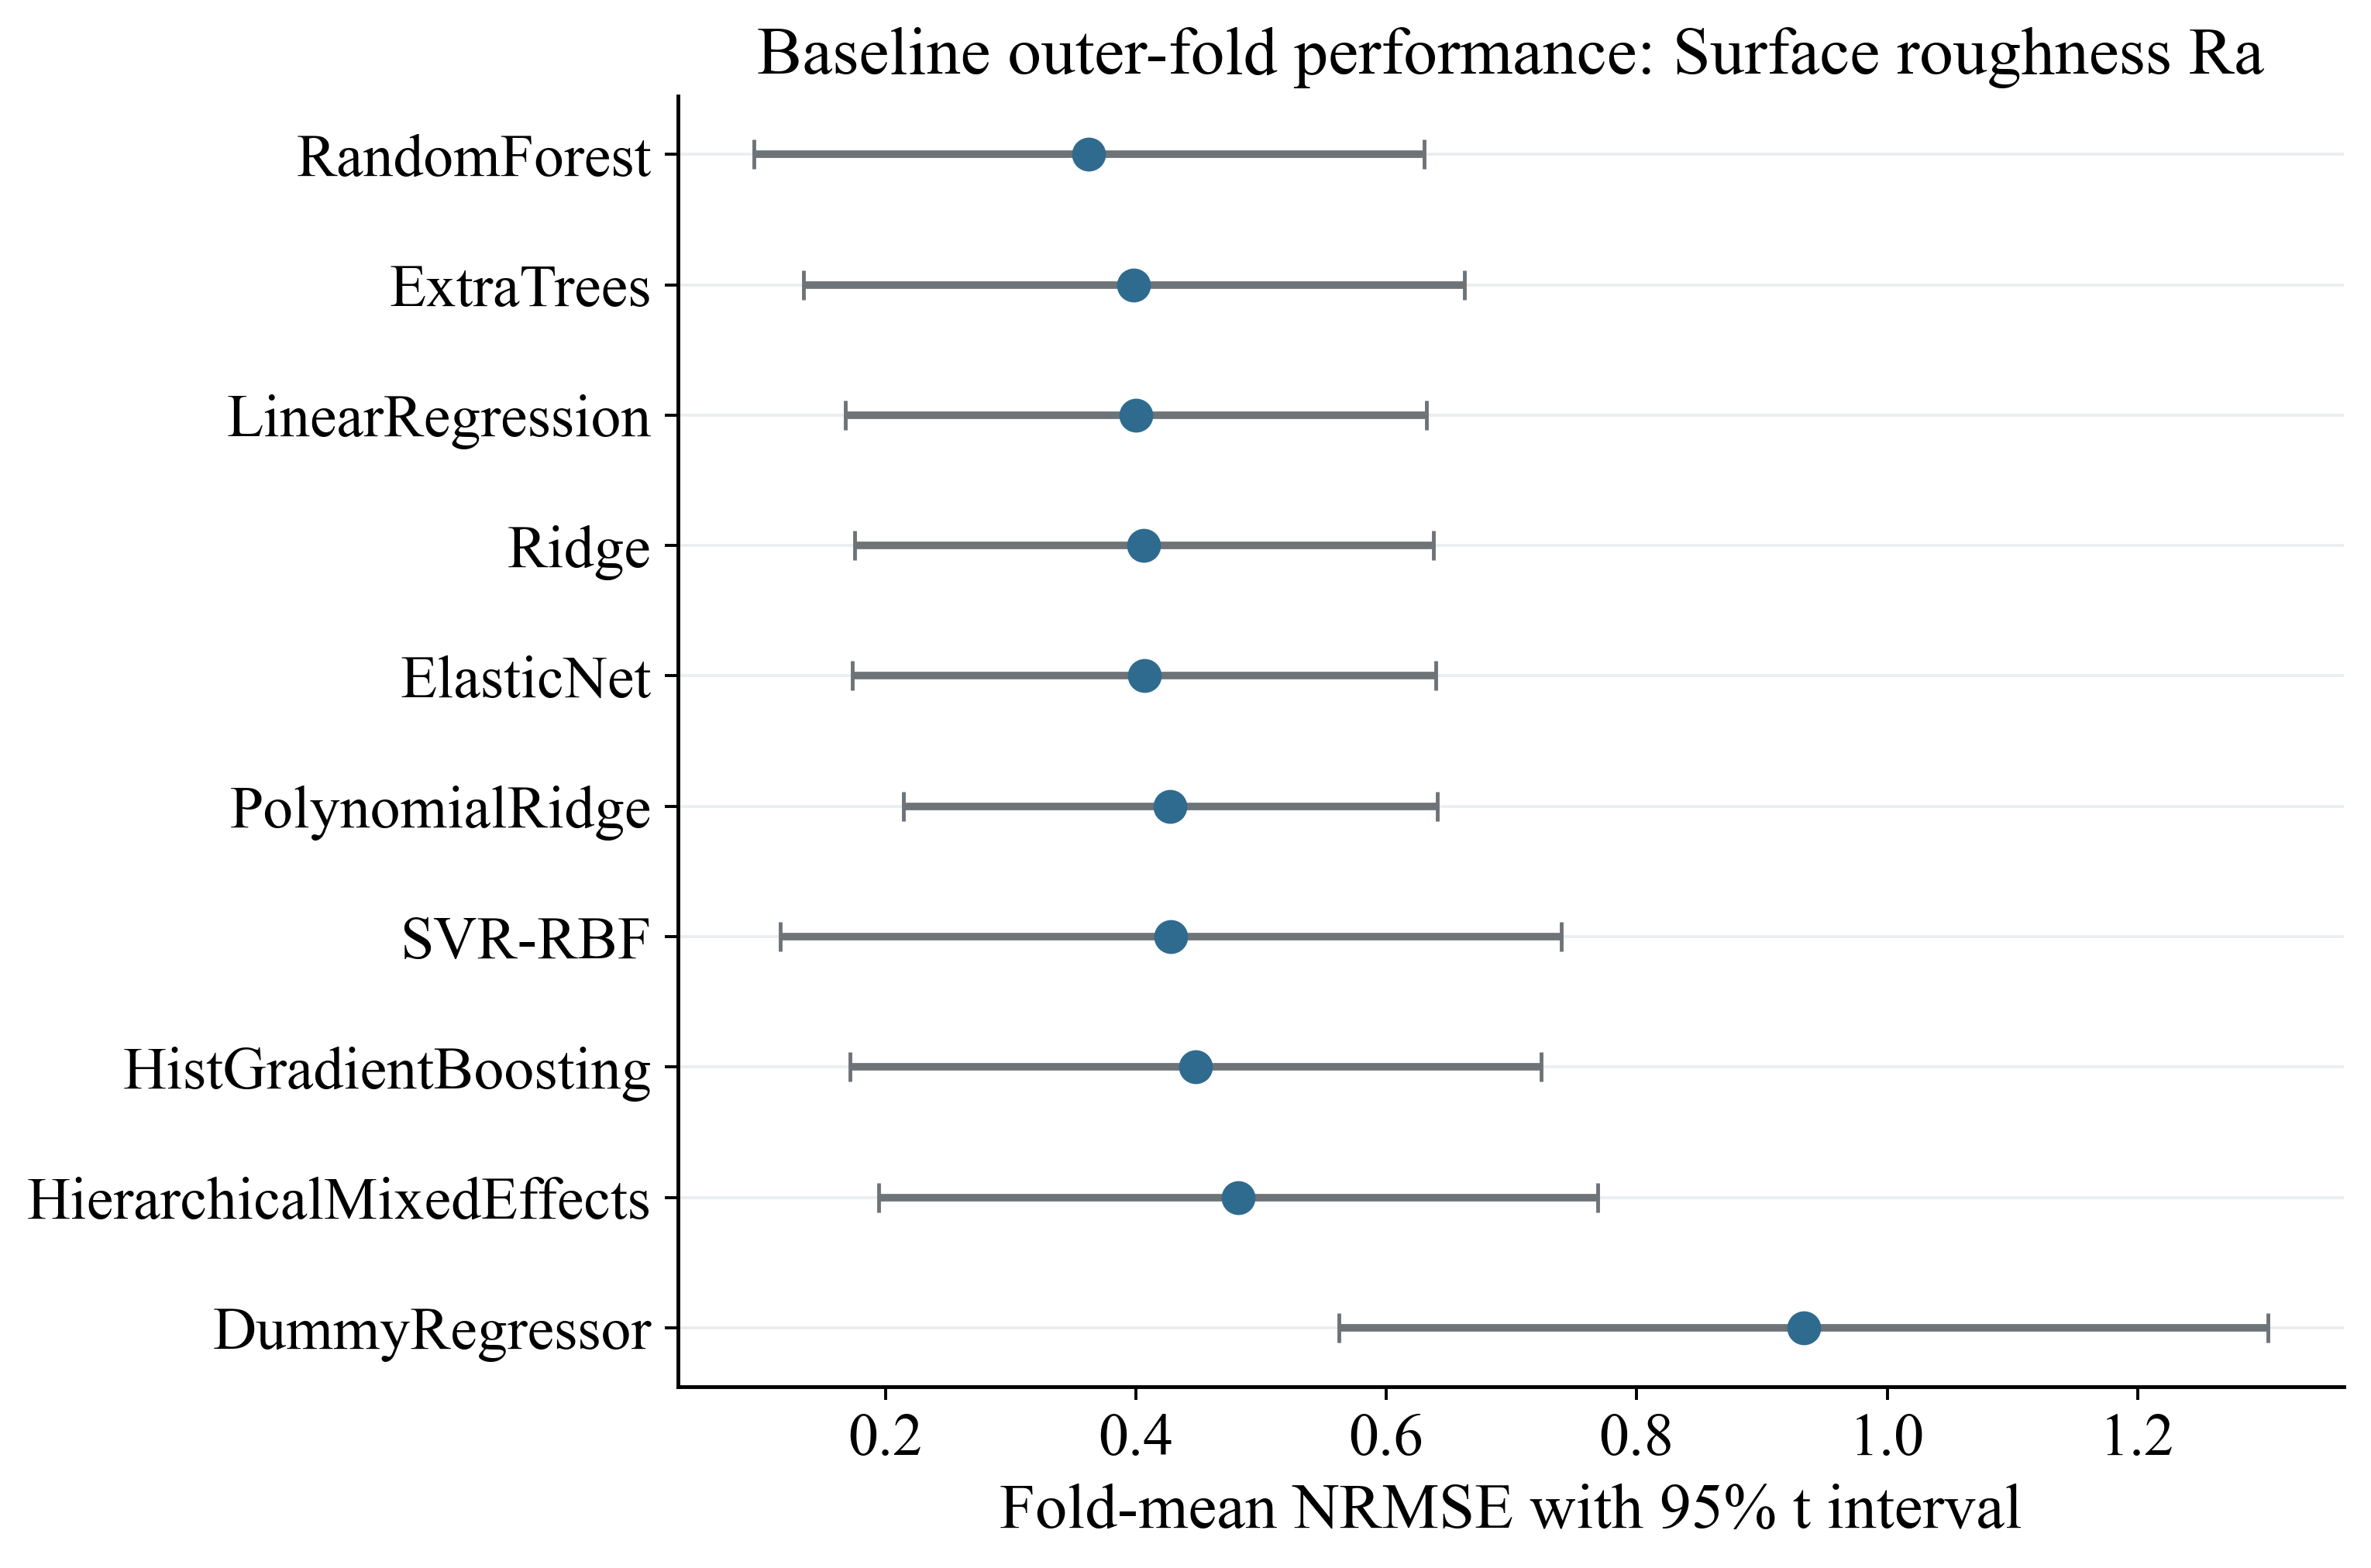

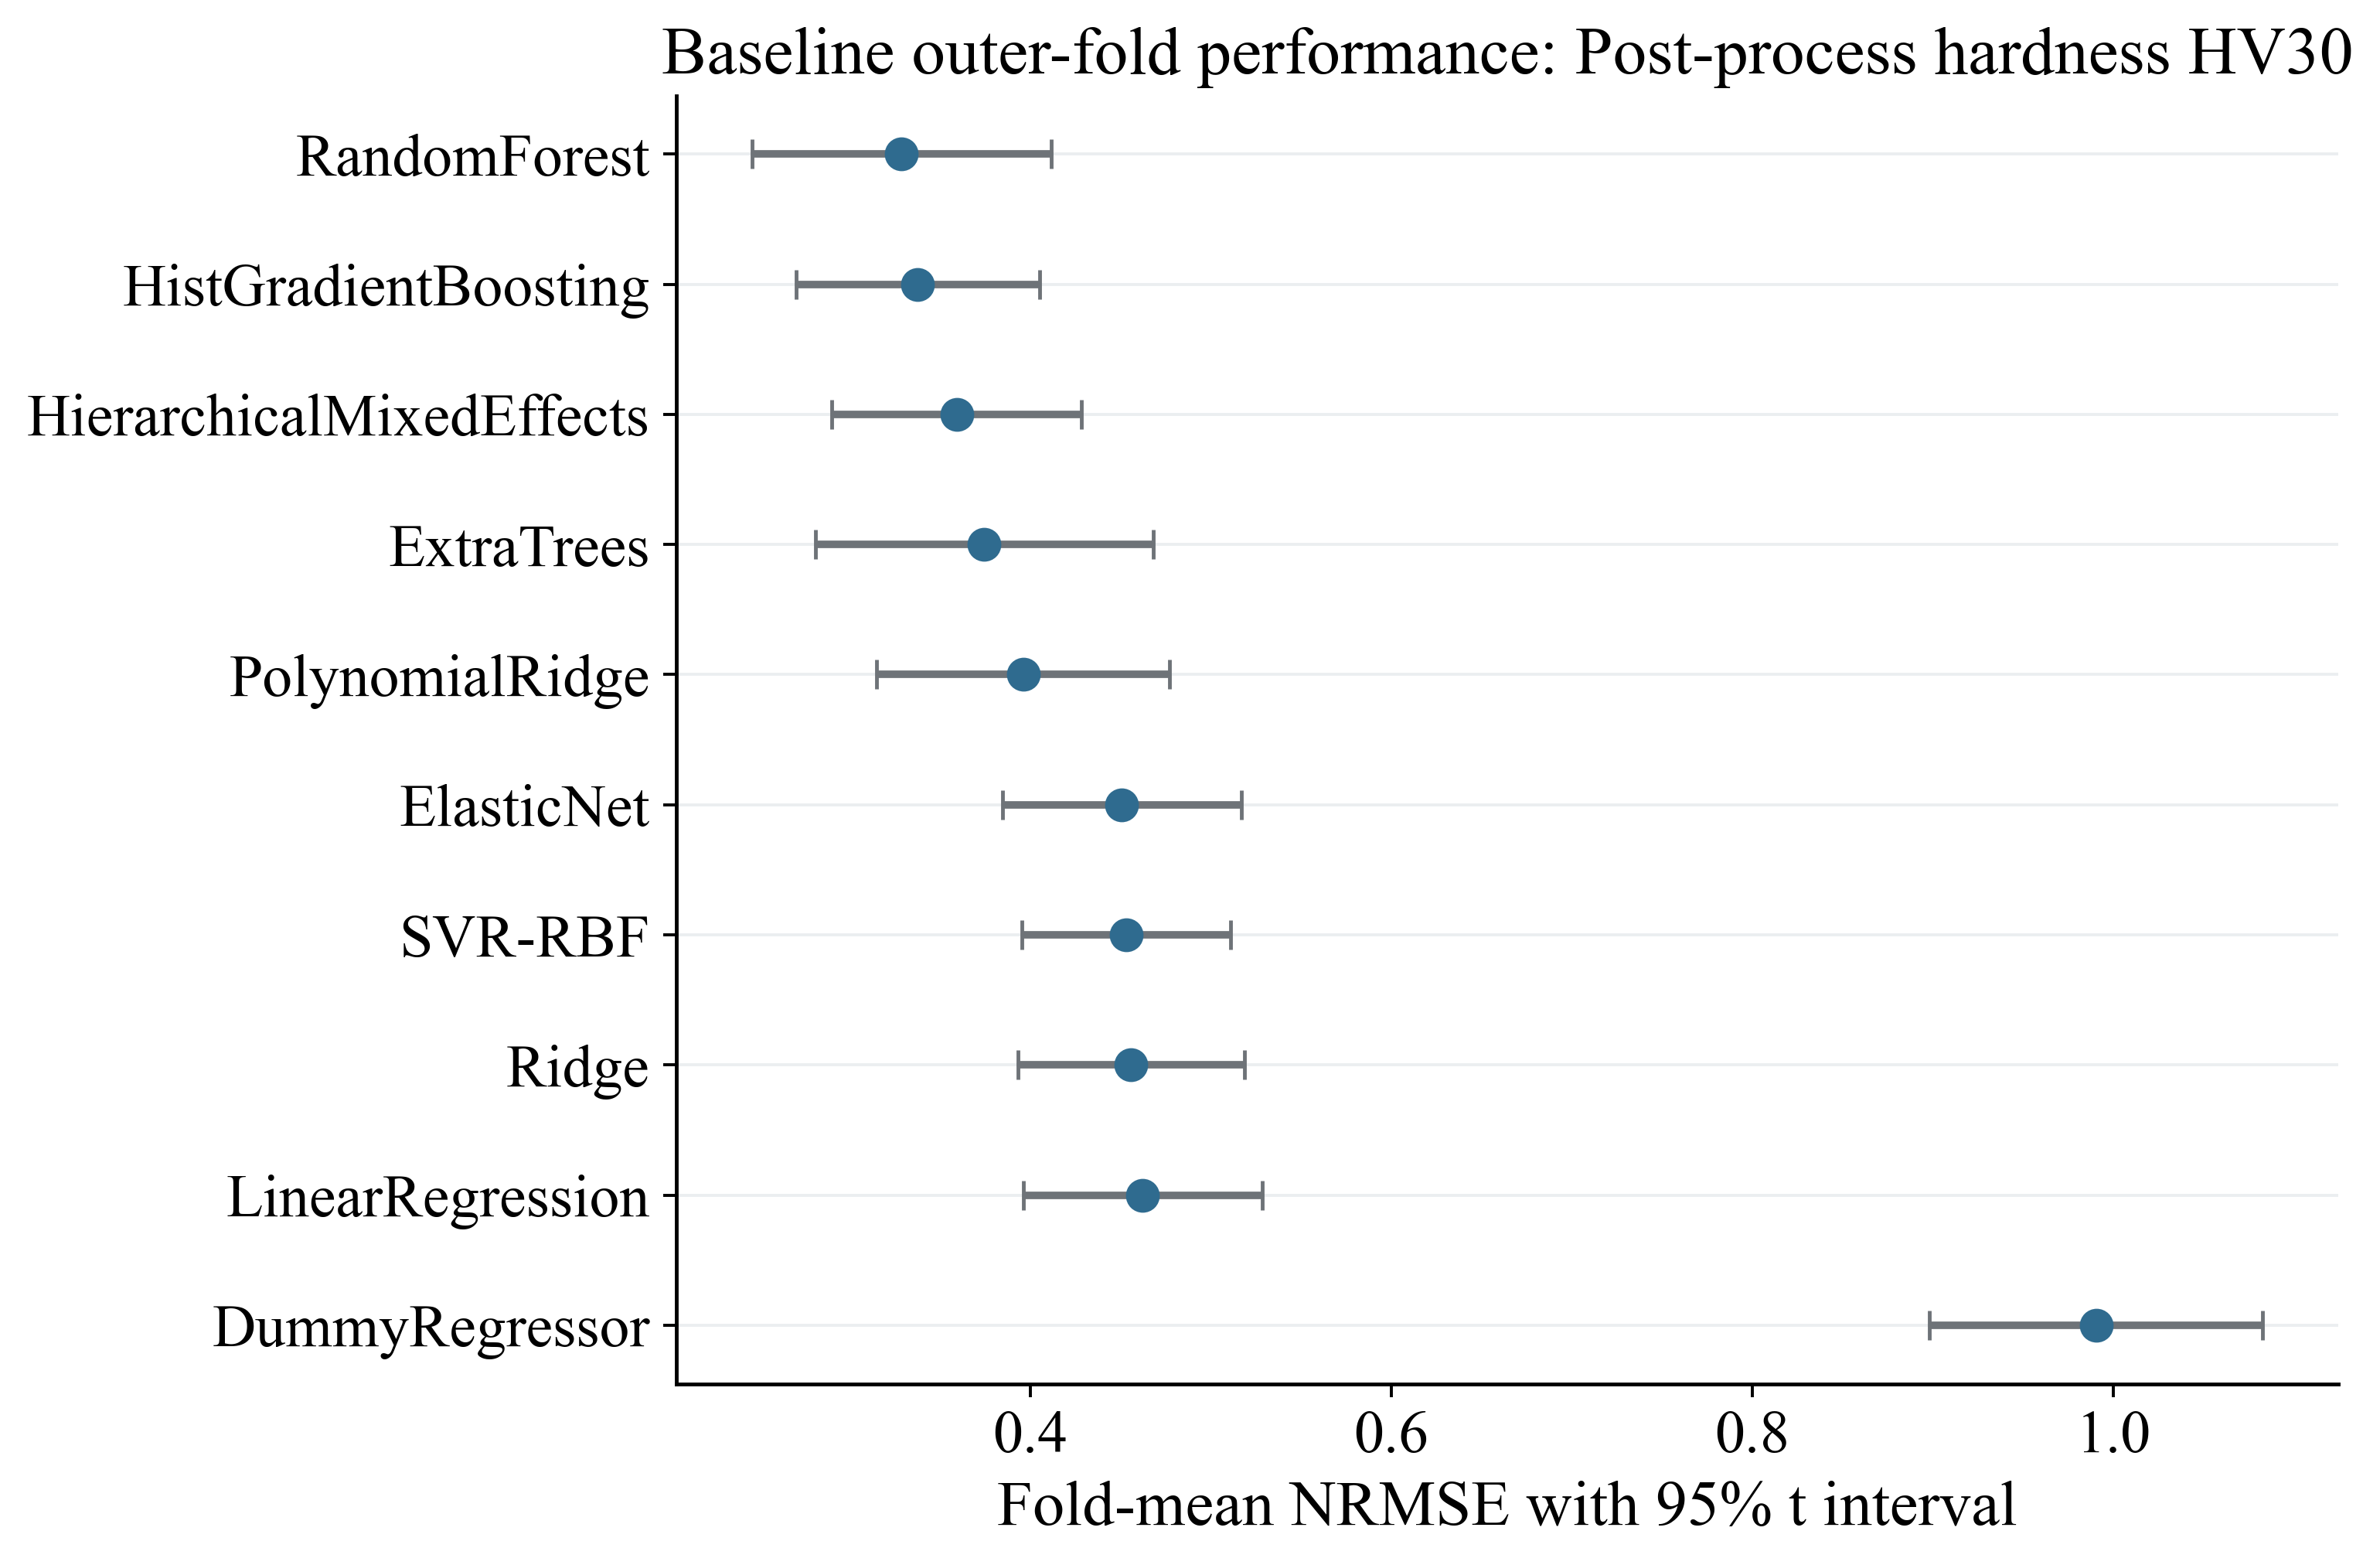

**Interpretation.** `RandomForest` has the lowest baseline point estimate (mean target-wise NRMSE = 0.416). Fold intervals remain wide because each outer test fold contains only three specimens, so ranking uncertainty must accompany point estimates.

In [8]:
plot_frame = baseline_fold_summary.copy()
target_specs = [
    (TARGETS[0], "Surface roughness Ra", "ra"),
    (TARGETS[1], "Post-process hardness HV30", "hv30"),
]
for target, title, slug in target_specs:
    part = plot_frame[plot_frame.target.eq(target)].sort_values("NRMSE_mean", ascending=False)
    y_positions = np.arange(len(part))
    errors = np.vstack([
        part.NRMSE_mean - part.NRMSE_95CI_low,
        part.NRMSE_95CI_high - part.NRMSE_mean,
    ])
    fig, axis = plt.subplots(figsize=(9.6, 6.8))
    axis.errorbar(part.NRMSE_mean, y_positions, xerr=errors, fmt="o", color=PALETTE["blue"],
                  ecolor=PALETTE["gray"], capsize=4, markersize=8)
    axis.set_yticks(y_positions, labels=part.model)
    axis.set_title(f"Baseline outer-fold performance: {title}")
    axis.set_xlabel("Fold-mean NRMSE with 95% t interval")
    axis.set_ylabel("")
    axis.grid(axis="x")
    fig.subplots_adjust(left=0.34, right=0.98, top=0.88, bottom=0.18)
    save_scientific_figure(fig, f"baseline_fold_nrmse_{slug}", part)
    display(fig)
    plt.close(fig)

best_baseline = baseline_ranking.iloc[0].model
best_value = baseline_ranking.iloc[0].mean_NRMSE
display(Markdown(
    f"**Interpretation.** `{best_baseline}` has the lowest baseline point estimate "
    f"(mean target-wise NRMSE = {best_value:.3f}). Fold intervals remain wide because each "
    "outer test fold contains only three specimens, so ranking uncertainty must accompany point estimates."
))

## 7. Held-out prediction and residual diagnostics for the strongest baseline


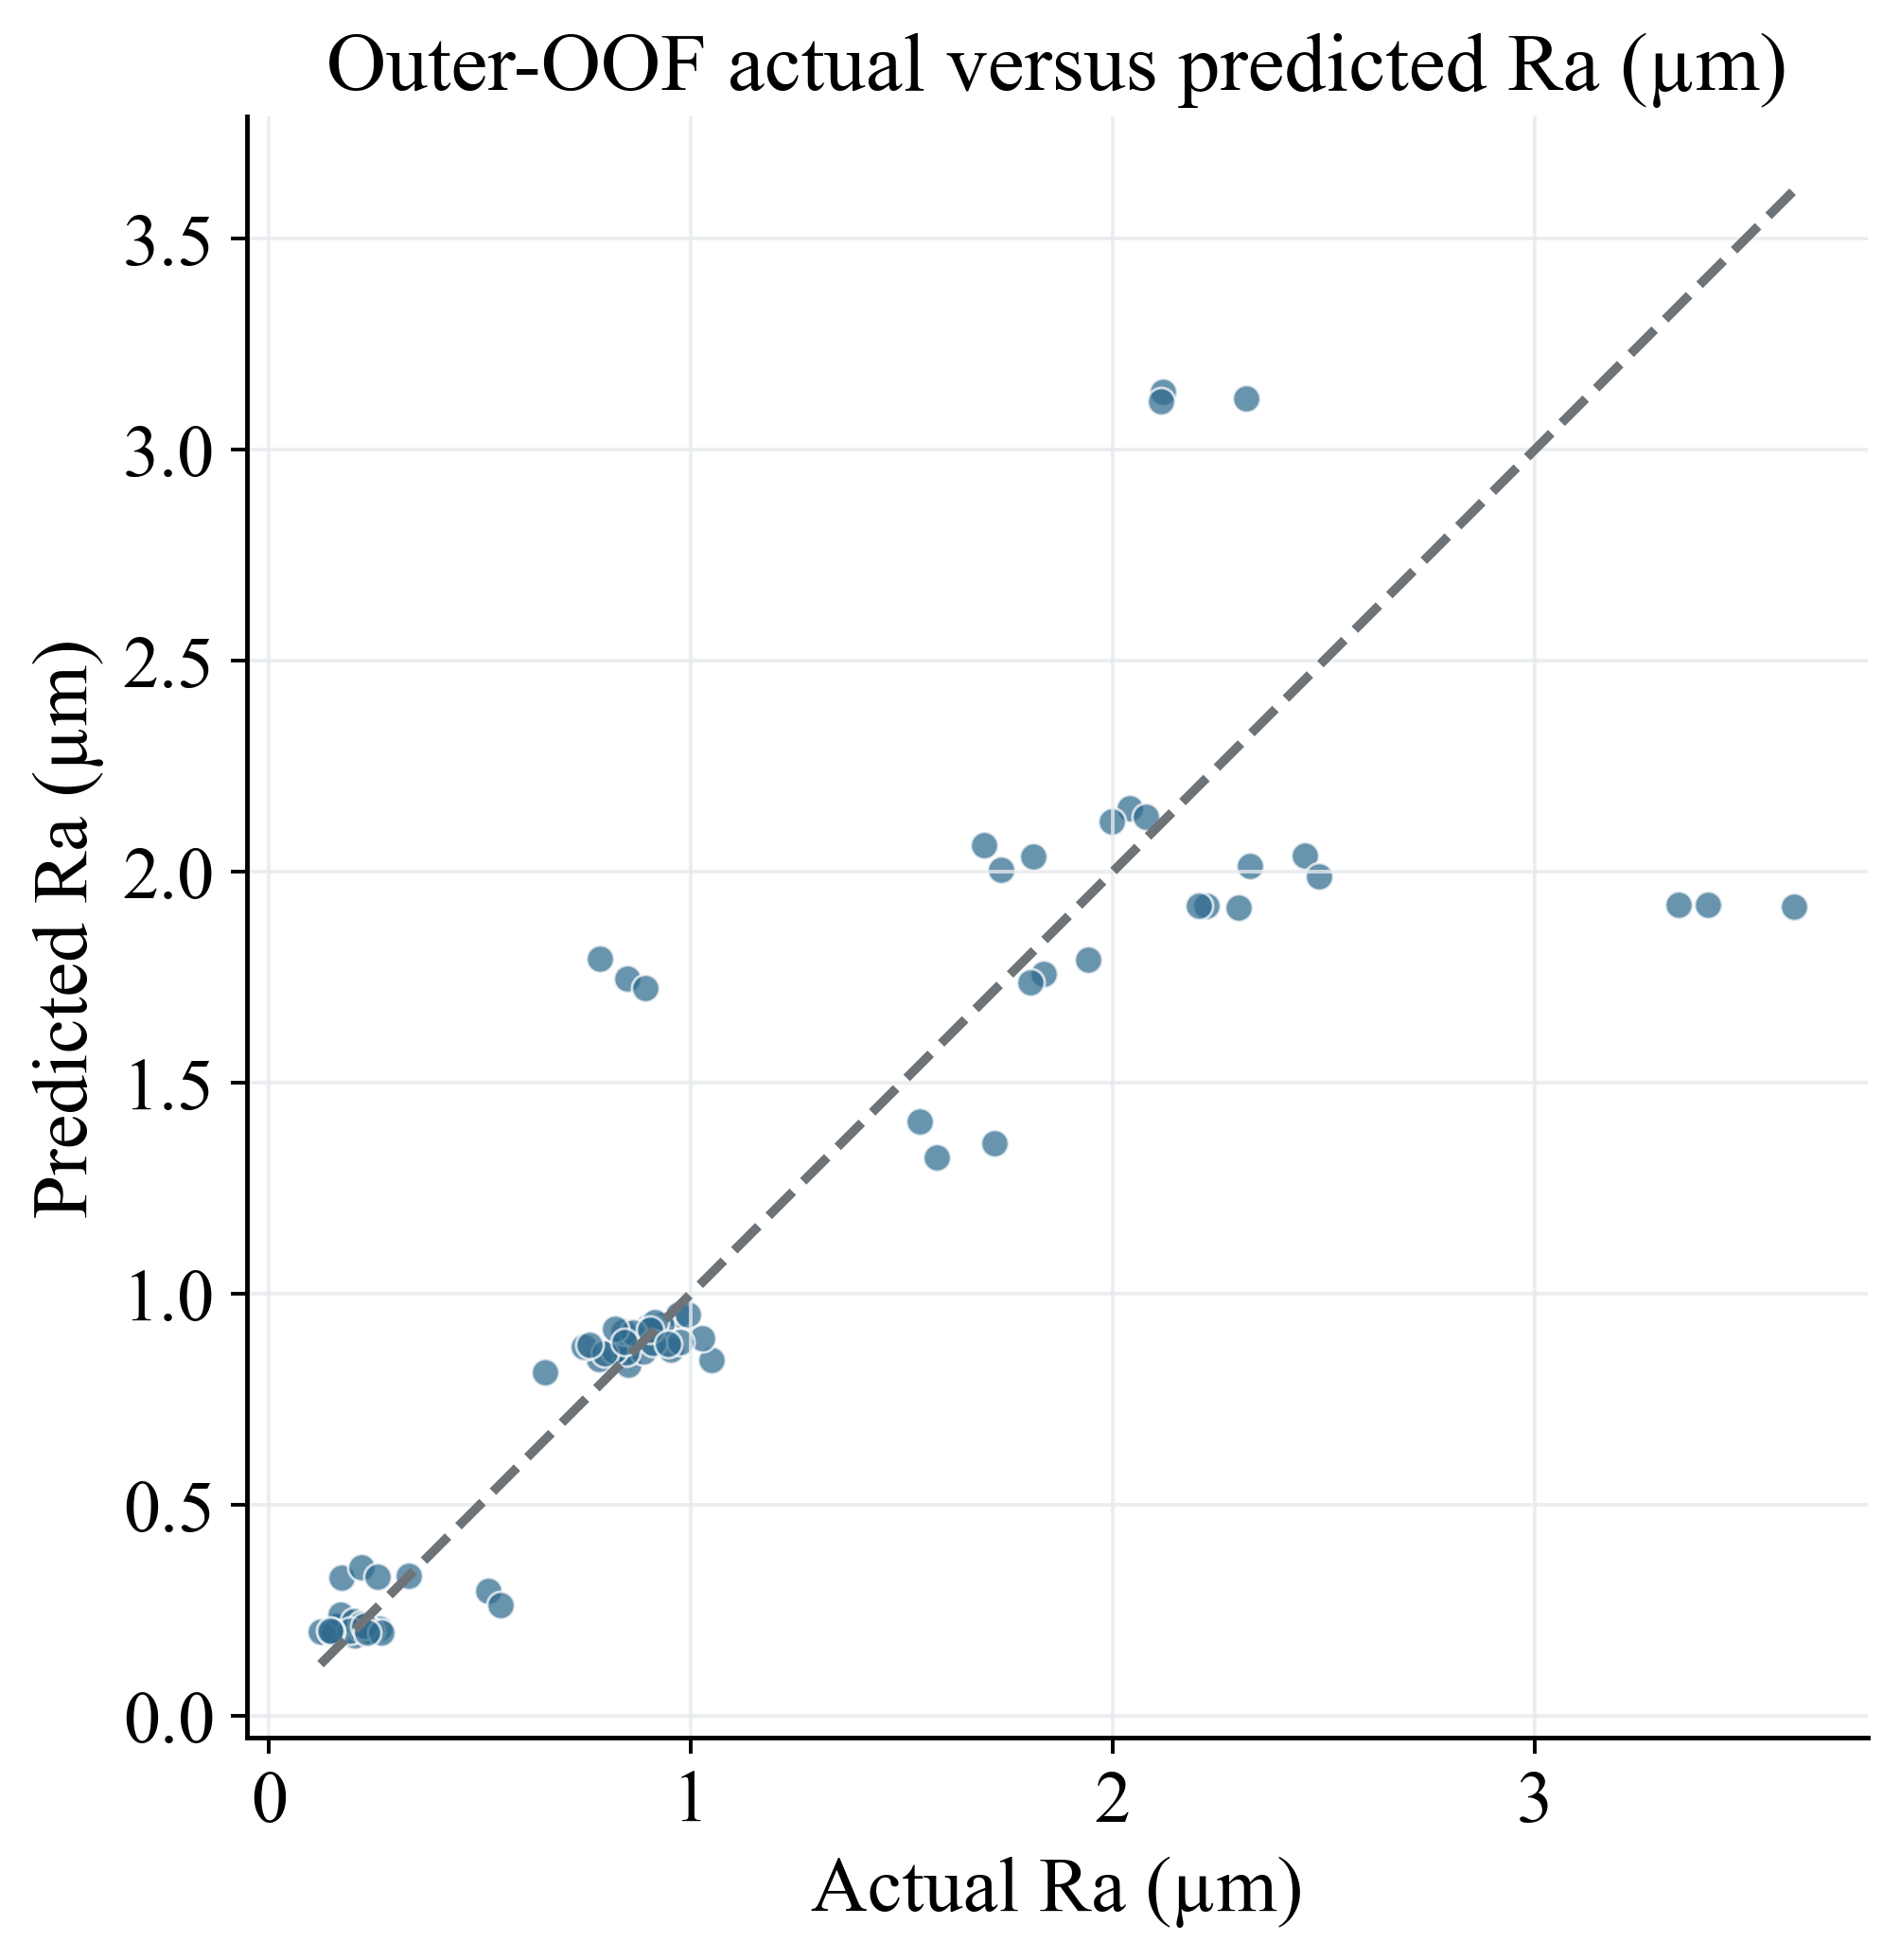

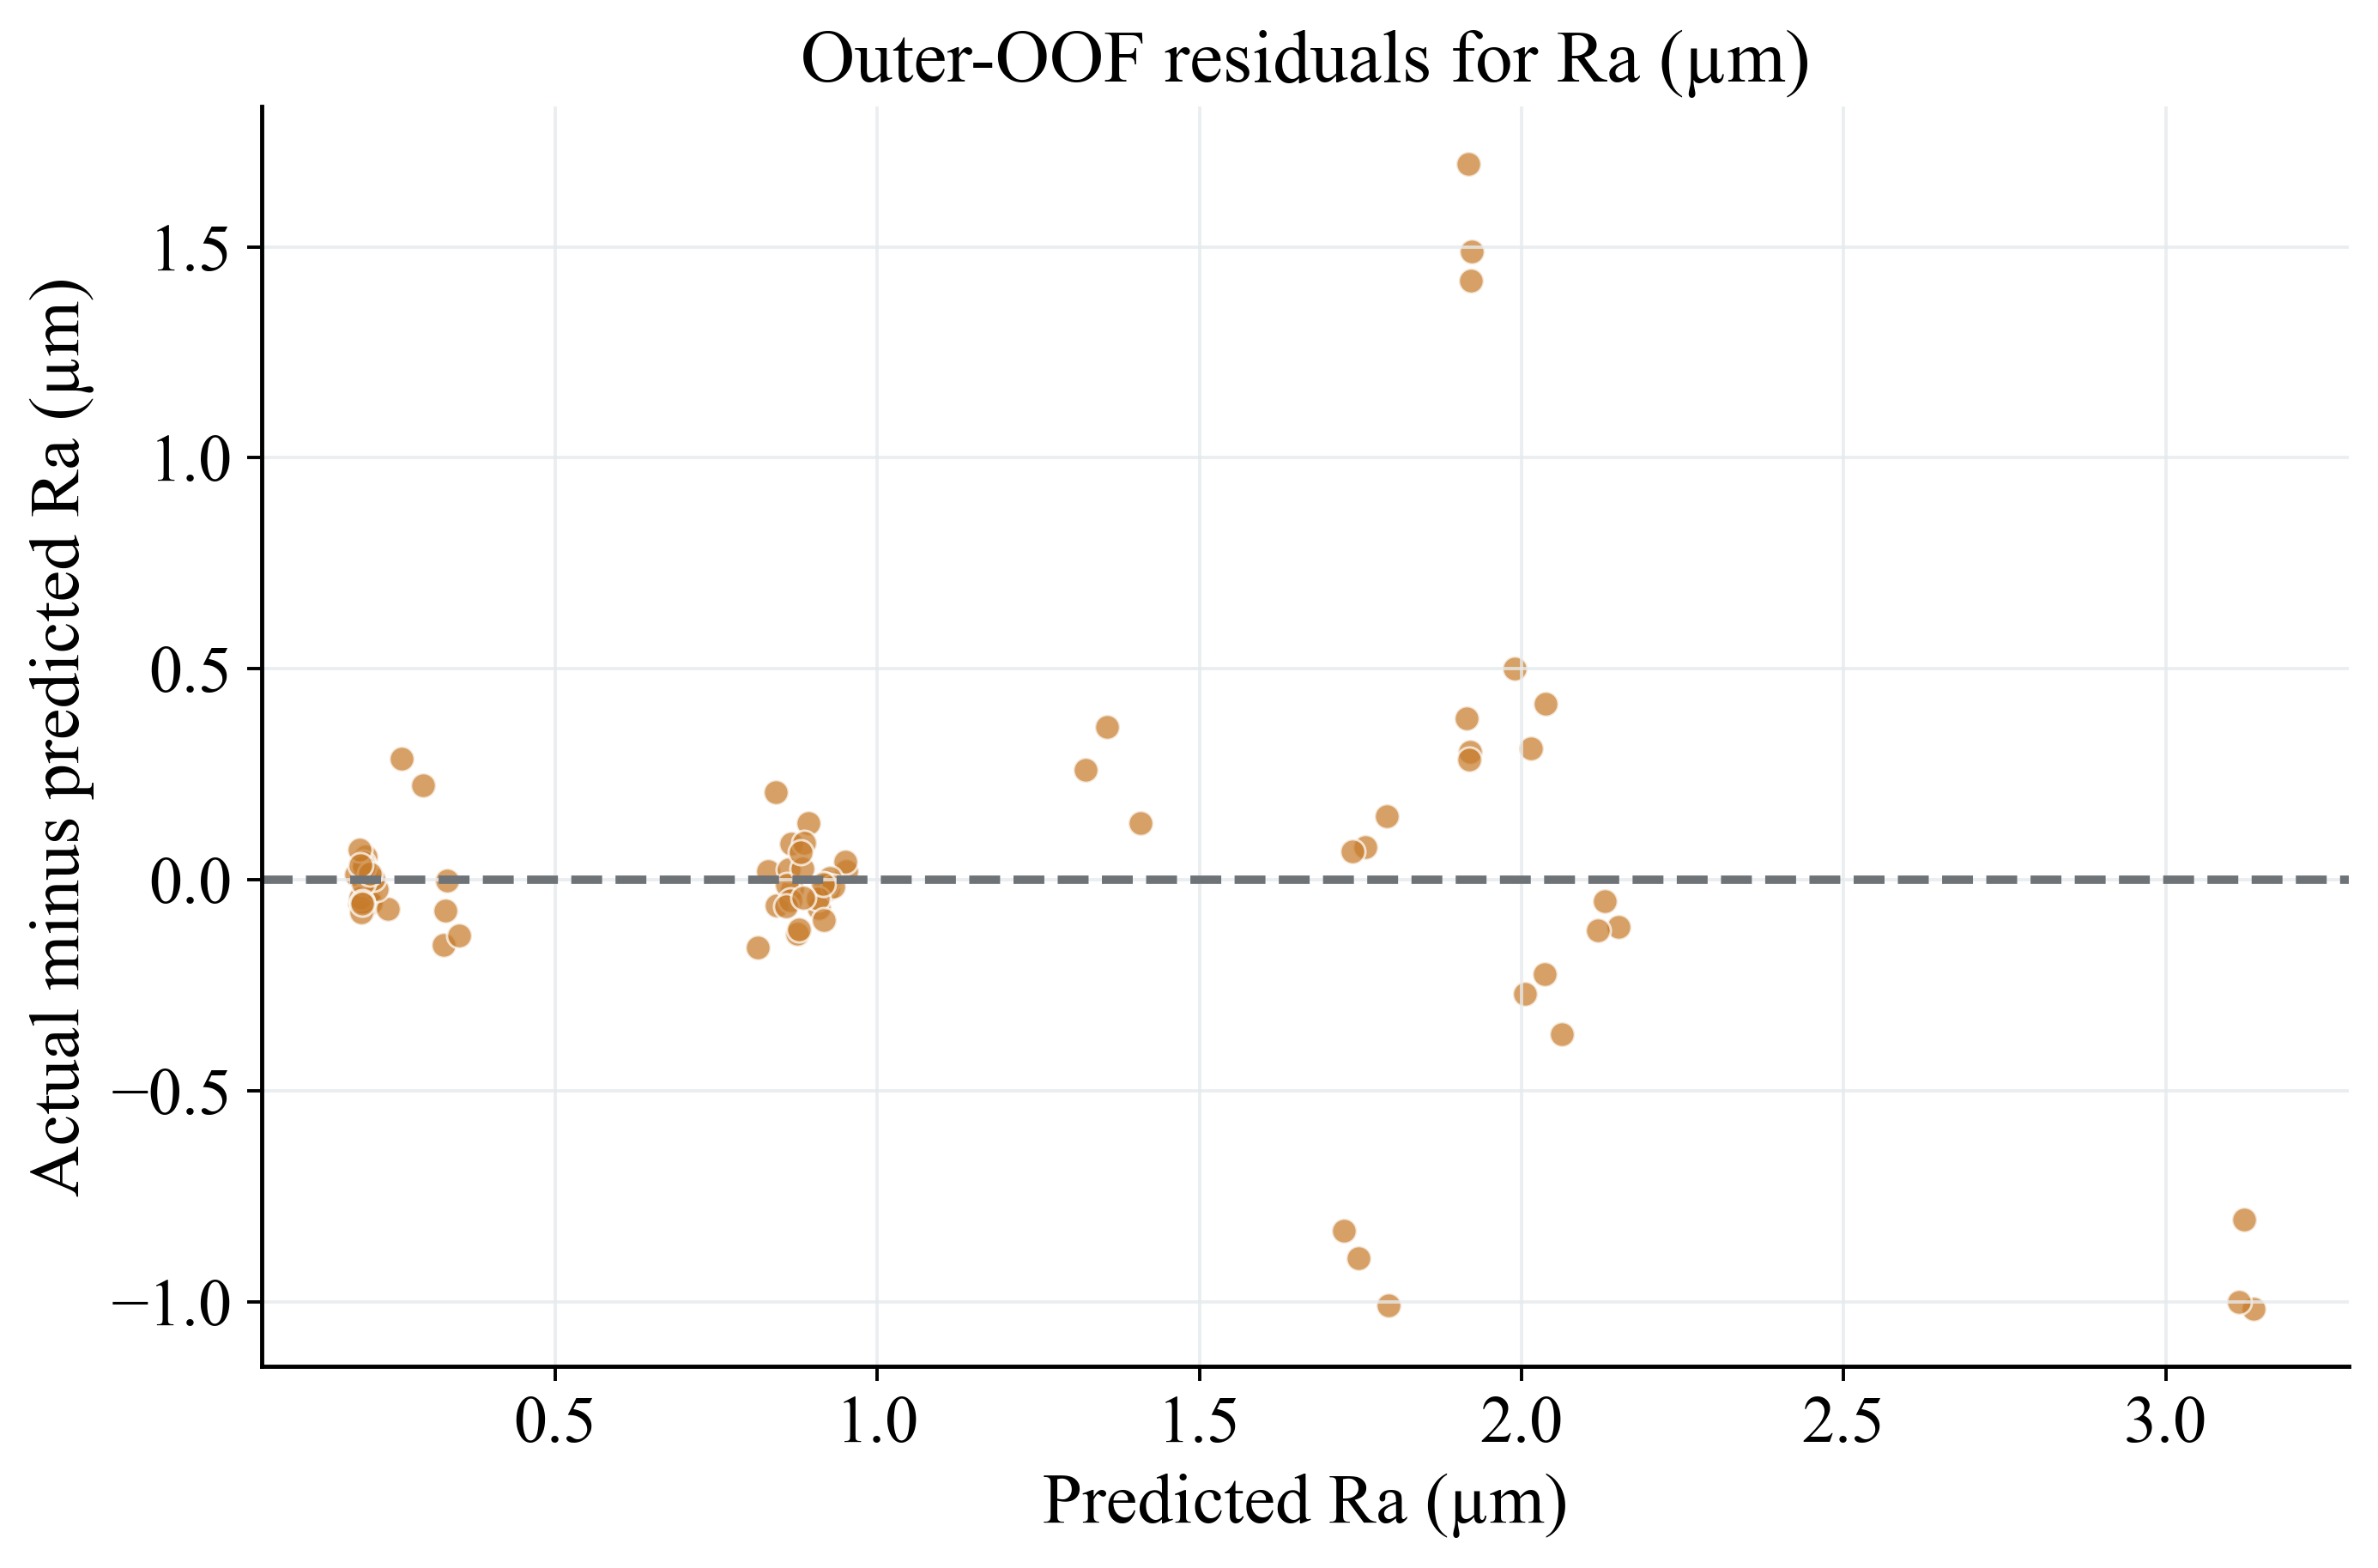

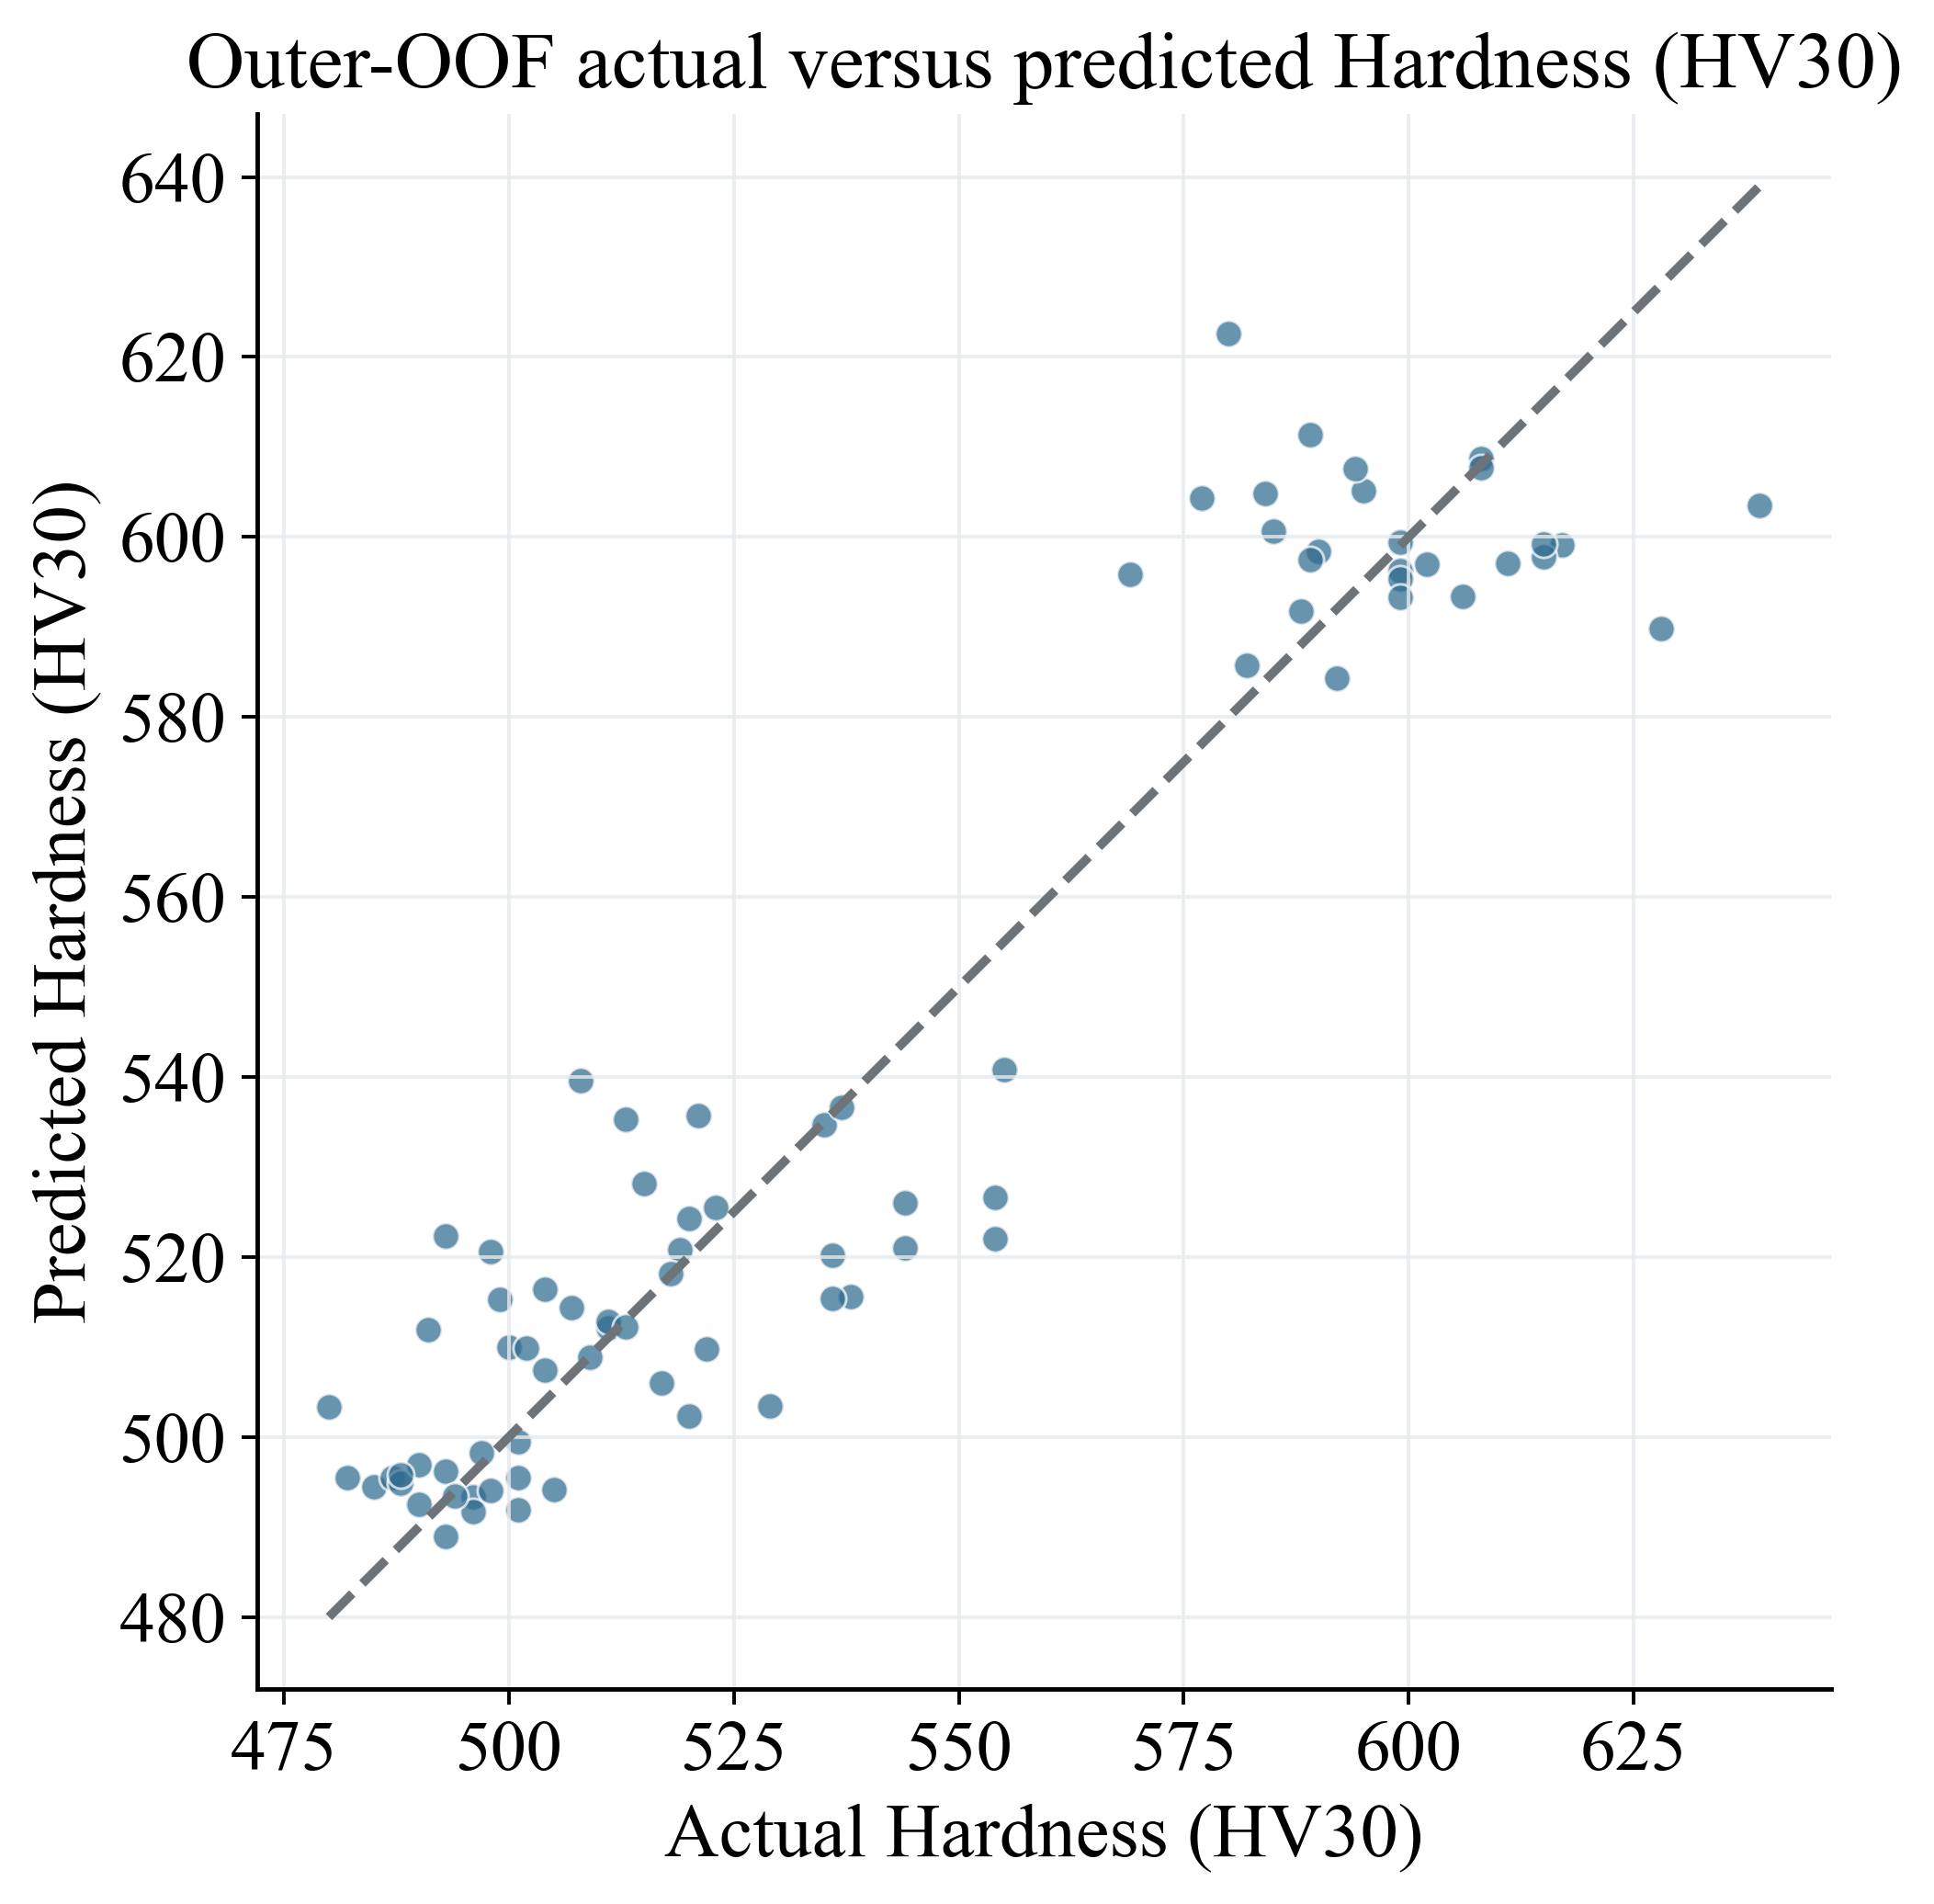

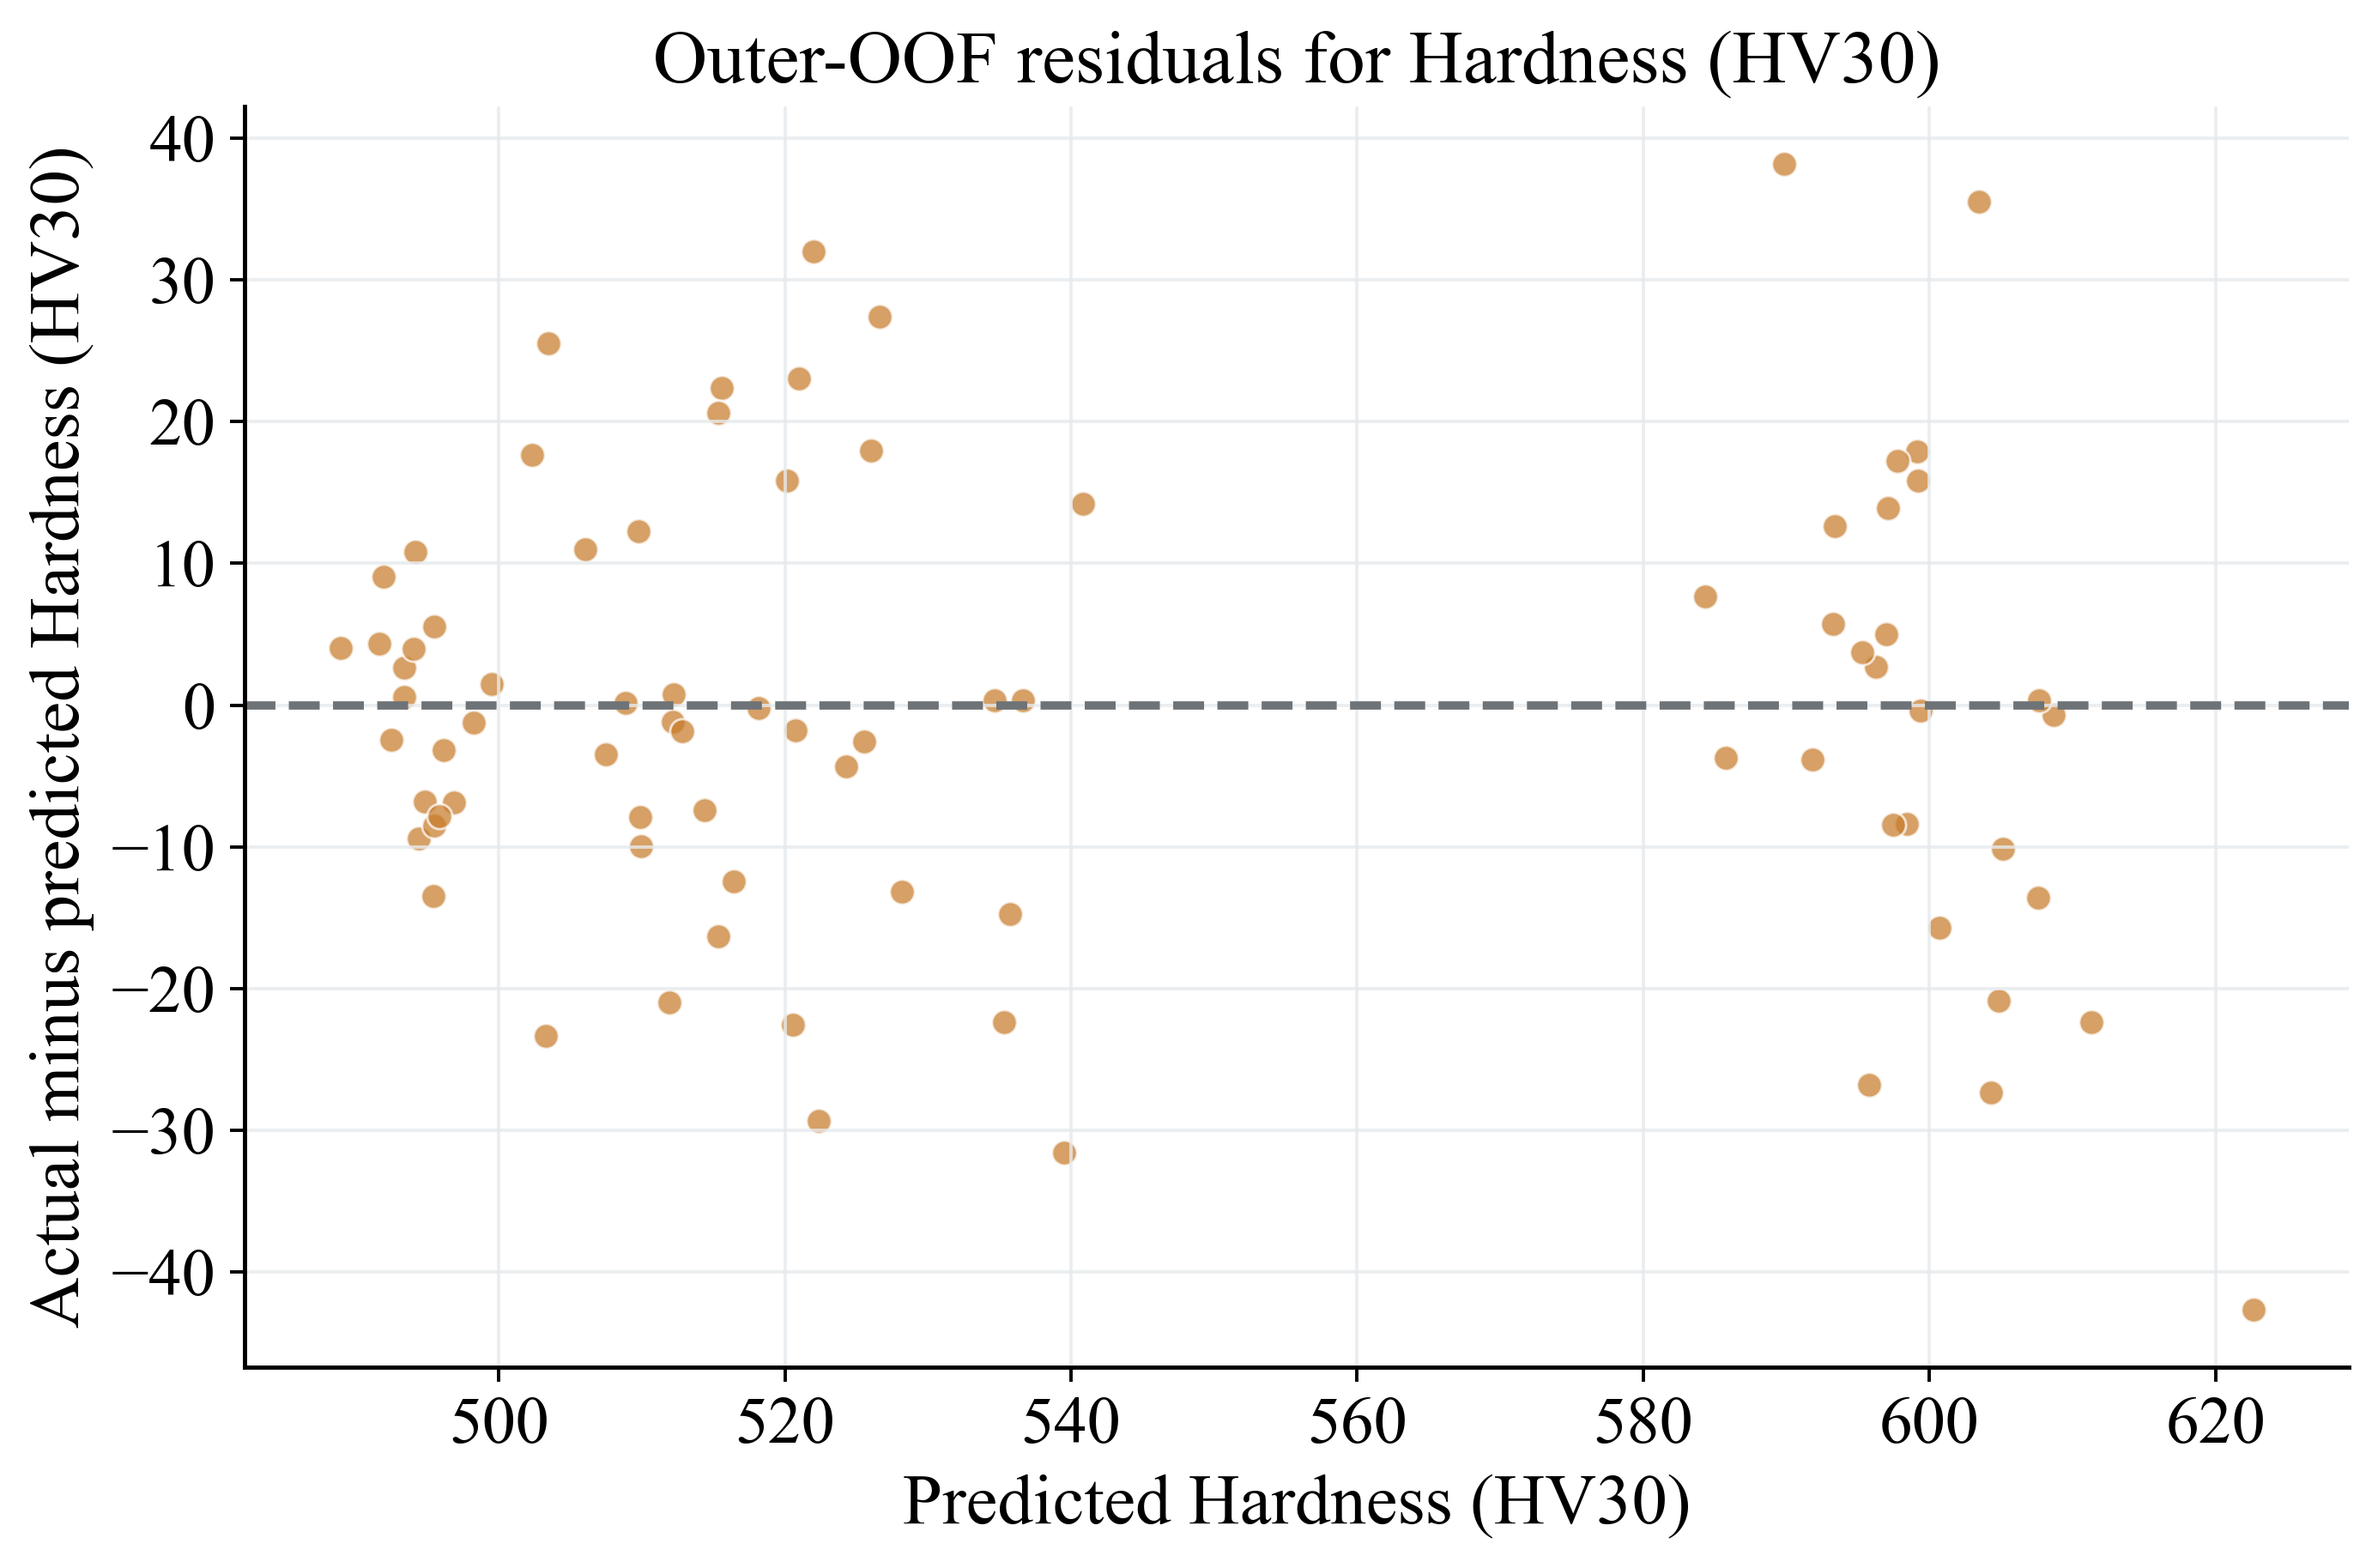

**Interpretation.** The plots use only outer-OOF predictions, so visible bias and spread are generalization diagnostics rather than training fit. Different residual scales for Ra and HV30 reinforce the requirement for target-wise physical-unit metrics.

In [9]:
best_baseline = baseline_ranking.iloc[0].model
diagnostic = saved_predictions[saved_predictions.model.eq(best_baseline)].copy()
target_specs = [
    (TARGETS[0], "Ra (µm)", "ra"),
    (TARGETS[1], "Hardness (HV30)", "hv30"),
]
for target, label, slug in target_specs:
    part = diagnostic[diagnostic.target.eq(target)]
    lower = min(part.y_true.min(), part.y_pred.min())
    upper = max(part.y_true.max(), part.y_pred.max())

    fig, axis = plt.subplots(figsize=(7.2, 6.2))
    axis.scatter(part.y_true, part.y_pred, color=PALETTE["blue"], alpha=0.72,
                 edgecolor="white", linewidth=0.6)
    axis.plot([lower, upper], [lower, upper], linestyle="--", color=PALETTE["gray"])
    axis.set_title(f"Outer-OOF actual versus predicted {label}")
    axis.set_xlabel(f"Actual {label}")
    axis.set_ylabel(f"Predicted {label}")
    axis.set_aspect("equal", adjustable="box")
    fig.tight_layout()
    save_scientific_figure(fig, f"best_baseline_actual_predicted_{slug}", part)
    display(fig)
    plt.close(fig)

    residual = part.y_true - part.y_pred
    residual_source = part.copy()
    residual_source["residual"] = residual
    fig, axis = plt.subplots(figsize=(8.2, 5.5))
    axis.scatter(part.y_pred, residual, color=PALETTE["orange"], alpha=0.72,
                 edgecolor="white", linewidth=0.6)
    axis.axhline(0, linestyle="--", color=PALETTE["gray"])
    axis.set_title(f"Outer-OOF residuals for {label}")
    axis.set_xlabel(f"Predicted {label}")
    axis.set_ylabel(f"Actual minus predicted {label}")
    fig.tight_layout()
    save_scientific_figure(fig, f"best_baseline_residuals_{slug}", residual_source)
    display(fig)
    plt.close(fig)

display(Markdown(
    "**Interpretation.** The plots use only outer-OOF predictions, so visible bias and spread are "
    "generalization diagnostics rather than training fit. Different residual scales for Ra and HV30 "
    "reinforce the requirement for target-wise physical-unit metrics."
))

## 8. Computational efficiency of the baseline family


In [10]:
timing_summary = baseline_timing.groupby("model", as_index=False).agg(
    mean_fit_seconds=("fit_seconds", "mean"),
    mean_inference_ms_per_sample=("inference_ms_per_sample", "mean"),
    median_serialized_bytes=("serialized_bytes", "median"),
)
timing_summary.to_csv(METRIC_DIR / "baseline_timing_complexity_summary.csv", index=False)
reloaded_models = joblib.load(MODEL_DIR / "baseline_outer_fold_models.joblib")
if len(reloaded_models) != 9 * len(BASELINE_CANDIDATES) * len(TARGETS):
    raise RuntimeError("The baseline model bundle is incomplete.")
mixed_diagnostics = []
for record in reloaded_models:
    if record["model"] != "HierarchicalMixedEffects":
        continue
    fitted = record["fitted_model"]
    mixed_diagnostics.append({
        "outer_fold": int(record["outer_fold"]), "target": record["target"],
        "converged": bool(fitted.converged_),
        "random_intercept_variance": float(fitted.random_intercept_variance_),
        "optimizer_used": fitted.optimizer_used_,
        "optimizer_fallback_used": bool(fitted.optimizer_fallback_used_),
        "boundary_fit": bool(fitted.random_intercept_boundary_fit_),
        "optimizer_attempts": "; ".join(
            f"{item['optimizer']}:{'converged' if item['converged'] else item['error'] or 'not_converged'}"
            for item in fitted.optimizer_attempts_
        ),
    })
mixed_diagnostics = pd.DataFrame(mixed_diagnostics)
mixed_diagnostics.to_csv(METRIC_DIR / "mixed_effects_fit_diagnostics.csv", index=False)
display_grouped_table(timing_summary.round(4), title="Baseline efficiency")
display_grouped_table(mixed_diagnostics.round(6), title="Mixed-effects convergence and boundary diagnostics")

**Baseline efficiency — Complete table**

model,mean_fit_seconds,mean_inference_ms_per_sample,median_serialized_bytes
DummyRegressor,0.000500,0.032300,559.000000
ElasticNet,0.001800,0.091600,1361.000000
ExtraTrees,0.085700,1.390900,397575.000000
HierarchicalMixedEffects,0.021100,0.082400,1108.000000
HistGradientBoosting,0.447300,3.844200,103520.500000
LinearRegression,0.001600,0.081400,1308.000000
PolynomialRidge,0.001900,0.101500,1720.000000
RandomForest,0.132900,1.381600,896753.500000
Ridge,0.001600,0.078900,1273.000000
SVR-RBF,0.002000,0.093300,6145.000000


**Mixed-effects convergence and boundary diagnostics — target=surface_roughness_Ra_um — Additional reported attributes (part 1/2)**

target,outer_fold,converged,random_intercept_variance,optimizer_used,optimizer_fallback_used,boundary_fit
surface_roughness_Ra_um,1,True,0.197782,lbfgs,False,False
surface_roughness_Ra_um,2,True,0.193716,lbfgs,False,False
surface_roughness_Ra_um,3,True,0.198285,lbfgs,False,False
surface_roughness_Ra_um,4,True,0.191475,lbfgs,False,False
surface_roughness_Ra_um,5,True,0.193147,lbfgs,False,False
surface_roughness_Ra_um,6,True,0.187746,lbfgs,False,False
surface_roughness_Ra_um,7,True,0.071863,lbfgs,False,False
surface_roughness_Ra_um,8,True,0.199969,lbfgs,False,False
surface_roughness_Ra_um,9,True,0.116635,lbfgs,False,False


**Mixed-effects convergence and boundary diagnostics — target=surface_roughness_Ra_um — Additional reported attributes (part 2/2)**

target,outer_fold,optimizer_attempts
surface_roughness_Ra_um,1,lbfgs:converged
surface_roughness_Ra_um,2,lbfgs:converged
surface_roughness_Ra_um,3,lbfgs:converged
surface_roughness_Ra_um,4,lbfgs:converged
surface_roughness_Ra_um,5,lbfgs:converged
surface_roughness_Ra_um,6,lbfgs:converged
surface_roughness_Ra_um,7,lbfgs:converged
surface_roughness_Ra_um,8,lbfgs:converged
surface_roughness_Ra_um,9,lbfgs:converged


**Mixed-effects convergence and boundary diagnostics — target=post_process_hardness_HV30 — Additional reported attributes (part 1/2)**

target,outer_fold,converged,random_intercept_variance,optimizer_used,optimizer_fallback_used,boundary_fit
post_process_hardness_HV30,1,True,8.947235,lbfgs,False,False
post_process_hardness_HV30,2,True,7.698294,lbfgs,False,False
post_process_hardness_HV30,3,True,11.979082,lbfgs,False,False
post_process_hardness_HV30,4,True,8.777779,lbfgs,False,False
post_process_hardness_HV30,5,True,12.101766,lbfgs,False,False
post_process_hardness_HV30,6,True,19.418336,lbfgs,False,False
post_process_hardness_HV30,7,True,3.689069,lbfgs,False,False
post_process_hardness_HV30,8,True,37.857603,lbfgs,False,False
post_process_hardness_HV30,9,True,1.500578,lbfgs,False,False


**Mixed-effects convergence and boundary diagnostics — target=post_process_hardness_HV30 — Additional reported attributes (part 2/2)**

target,outer_fold,optimizer_attempts
post_process_hardness_HV30,1,lbfgs:converged
post_process_hardness_HV30,2,lbfgs:converged
post_process_hardness_HV30,3,lbfgs:converged
post_process_hardness_HV30,4,lbfgs:converged
post_process_hardness_HV30,5,lbfgs:converged
post_process_hardness_HV30,6,lbfgs:converged
post_process_hardness_HV30,7,lbfgs:converged
post_process_hardness_HV30,8,lbfgs:converged
post_process_hardness_HV30,9,lbfgs:converged


## Limitations and hand-off

Baseline estimates remain uncertain because only 27 specimen groups are available and each outer fold contains three specimens. Hyperparameters are selected by grouped inner OOF only; no outer held-out outcome is used for tuning. Mixed-effects convergence, optimizer fallback, random-intercept variance, and boundary fits are reported explicitly. No methodologically compatible independent dataset containing the required process structure and paired Ra/HV30 outcomes was identified. Therefore, independent external validation was not performed. The study relies on leakage-safe specimen-grouped nested cross-validation and complementary internal robustness analyses, and all conclusions are restricted to the investigated 51CrV4 factorial domain. Notebook 04 may introduce modern and compact deep models only under the identical folds, features, metrics, and OOF contract.
